# EXP_11. ¿Combinar dos modelos mejora a cada uno por separado?

**Ronda exploratoria, sin entrenamientos nuevos.** No elige el modelo final ni genera las 59 predicciones.

## 1. Qué aprendimos y qué pregunta queda

* **EXP_10** dejó a **K = MIX + K1 corregido** como alternativa documentada a MIX. K usa un contraste local: el verdor de la parcela frente al de sus vecinas.
* Una comparación posterior puso al **modelo de Jared (J)** en las mismas particiones. J usa un nivel por grupo regional y una variable elegida entre 148, casi siempre la anomalía de lluvia de octubre.
* J y K tuvieron un RMSE parecido, pero **mejoraban zonas distintas**: K en Chignahuapan, J fuera de Chignahuapan.

**Pregunta:** ¿una mezcla fija **E_JK = ½J + ½K** mejora a sus dos componentes? ¿O basta con mezclar K con algo más sencillo, como la media municipal (**E_MK = ½MUN + ½K**)?

**Advertencia desde el inicio:** esta pregunta nació *después* de ver esos resultados con las mismas 138 etiquetas. El registro previo limita decisiones nuevas, pero no vuelve independiente la evaluación. Las particiones "nuevas" reutilizan esas etiquetas.

## 2. Qué significa combinar predicciones

Cada modelo ya produjo, para cada parcela de validación, una predicción completa en t/ha. Combinar es promediarlas:

$$E_{JK} = 0.5\,\hat y_J + 0.5\,\hat y_K \qquad E_{MK} = 0.5\,\hat y_{MUN} + 0.5\,\hat y_K$$

No se entrena nada nuevo ni se eligen pesos. Promediar **predicciones completas** no es lo mismo que sumar a MIX las correcciones de J y K; eso sería otro procedimiento.

**Por qué podría mejorar.** Si $e_a$ y $e_b$ son los errores de dos modelos, el error cuadrático medio de su promedio es

$$\mathrm{MSE}\big(\tfrac{a+b}{2}\big) = \tfrac14\mathrm{MSE}_a + \tfrac14\mathrm{MSE}_b + \tfrac12\,\overline{e_a e_b}.$$

Cuanto menos se parezcan los errores, mayor es la ganancia. Si fueran idénticos, no habría ninguna.

## 3. Por qué estas dos mezclas

* **E_JK** es la hipótesis: J y K podrían compensarse porque usan información distinta (regional frente a local).
* **E_MK** es el **control**. Mezclar K con la media municipal también reduce a la mitad el peso de la interpolación espacial de MIX. Si E_MK mejorara tanto como E_JK, la ganancia vendría de "menos interpolación" y no de algo propio de Jared.

## 4. Qué se mantiene fijo

| Fijo | Valor |
| --- | --- |
| Predicciones de cada componente | Las existentes: MIX, MUN y K de EXP_10; J de la comparación verificada |
| Pesos | 0.5 y 0.5, sin búsqueda |
| Particiones | Históricas y nuevas (EXP_09), sin semillas nuevas |
| Población | SEEN135 principal; FULL138 como sensibilidad |
| Presupuesto | 2 fórmulas, 0 entrenamientos, 0 variables nuevas, 0 reglas por municipio |

No se probarán 25/75, stacking, gating ni mezclas regionales, aunque el resultado lo sugiera.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-09T04:38:11.951940+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


In [4]:
# @title Insumos verificados por SHA-256 y código fuente para inspección; no se ejecuta ningún entrenamiento { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'componentes': {'ruta_local': 'data/exp_11_combinacion_modelos/oof_componentes.csv', 'bytes': 809968, 'sha256': 'aac0347da4600a4fcdaa256860dd32969a07bea1fead74e7194405e740a229fa', 'uso': 'componentes', 'origen': 'data/exp_11_combinacion_modelos/oof_componentes.csv', 'bytes_zlib_base64': '...'}, 'verificacion_insumos': {'ruta_local': 'data/exp_11_combinacion_modelos/verificacion_insumos.json', 'bytes': 16255, 'sha256': 'a46351c6b3485f6e601888dec23858a06d5f5104d33f68c0b3cdc92a677d42be', 'uso': 'verificacion_insumos', 'origen': 'data/exp_11_combinacion_modelos/verificacion_insumos.json', 'bytes_zlib_base64': 'eNrFW9tuI7kRfZ+vEOYpQWY1LJLFi/OUh33IJJsAyQZYIAgaRbK40wtL7ehiZDbYT8pTPmF/LEXJF3m2bUsTtQ3MwK3mpdh16nKK3fz3m9nsbeX8kbrtJr+9mL3VSruvQH2l4rfKXhh1Ydw8GqtN/I1SF0q9fdeGLPjHfEnrLtNl3l5SobWMrXS55l1z7Vvj1bDqFkPhy0EatXdqP3R3p/X/u/yUG9/8/rvdpO3yb3+6vfxwe/GHt/L3H7uhIvKa19122WeZ/lNHl/2Sb4RvVtu9bN70/9zyRjosWsf+qh+6Ba0zrajrv9/SJT/ofkWrjfQaljJxHpZ5WBVabh72KX2VKf7VbRZX3fW6439dgZL2MA8BfLAQvVKgUfNX4B4MWPBmtVvriiuveJl7OpwA5gBKa6O0dRoBHd7NcDfyg4y9Wg1lm3nZXQ7t17DaUGk6/fdeQx/79WbY9b67J3eX3TDUJsSgend78y/f/PVruafmNhi0yhinvEHnrb3r8s3v9j2MAdSgtQ3a6GDsrv2nG1CWW74+TZwGEyzKdA5sxDFpRpahtEFvjA97aW9uJL6910Jfhq5fFr7iZelZkOoKrwt317TqKQm43bpfdrze0LLIrR9pNYbkg/l2SGhvUbRhtHbR+egFCXMjul/uJm+yqLs3r53Qy75Qs55DIfTDdi0WtOvAq74KMq1L96G5gdp7we1yO77k72WOZnsbHu684k6vcv+H7XLTWg6BvlPg7UStnZbDortasRh9d5U3Xbnv1hZowyGGXyRhTZvcLct13611t1D2oQA49/x46vw3dvlF2on/1+yycln4Rha+KW3xImh08XfBbLOi5boOq8XeOL4TC1hIMNr/Eh193y/pss389XJ207SaX316N5PQOgMbZncWP1vz7NDghzZgOVtw6Wn2aSb+cd3LtD//dynX++HRz2TCzO3Hr9bD5TD77tfvmphhxssZX87WedVfbVr/D7TiMp/9kaR5tZIR+5k+tV5//uNfd6KW/TW3hUhomn2/2l4Ns7Xcvfeb9YxkhTQ7fOY2CdWf/7P8rSxpduuO+/viwg+eaCYLFDm1l5Hz2Z+G9sSSR3auNd9nJBmeuexC7H1k/FGg/qGt/zBSrbab1uXtfP5+1/a+qbY9Df9z218Ncxl0j9z6I2l0rbu1nlBFzQ5jYkhKF62oYEKjKYVgoo0leW9cAQsmoi7RKJC4lryuwdzPmT7t84vRMgTxPhguNv2Cf5GI4VuFF9pdoJ8HFQyEm0T8ICALmB/76+FBSC60ofeSazqAZlxJDGpnXDcZ+P2ByvZaen8fRPe/82W/oK45jgS6FvL63GaQXsM8r68PhD1QFZcUU6kp2CIhvXoHVVeKRFAM6UwuJIeebPasrTccMOrIVvQhLCHm+6hyoCw03hzcHleVcBZzgfZC2bmT3Ab+gLPcDGyeJZlUUnkb2TL6od99mRoO19XzIq2GrhnRxY5dHJjWe2W6j/JXnqhv/OVOzr3EU2Tt2IyQoBthLf/cNP70bjobqEyb7YrXTxmAUc4VHbLk8uQrkPeqJiy2GhuEKmXLMRbASAGC5eBMyDpjkGYMsRozZgDOQ1AnWoBHPY0FPFDClPA/Juh1sL9b/VPgg8mavAmOcvFFu+SsZaUqMDgJjrYwgssSNzP4jI5sESpqQ2JtitiKGwPfeMATsQ9uIu9/qIQpwX9U0uugvxyE9s4X5THgs7MOQ5KEWGxMmazURVi9Zl0dKKeLFBuSRUOUOsD4nH2oKbFRlKTIKFDGgLfRhROBjxCnAf7u+afEfEzI68C90t2Oyz3l66n6Ig6OJZeiSUJ7oRIge59tEogVZl+qzolrEPYE7CwFnXOWtBA5+FHIvXOnIu7DNIg/UMGUqD8m6CWRv5ZqmpYnsDzttKpUfIbqLOuiQGhvyQRCk4miqZVMNCbbjCxeL44eEnlrSlIt+o/GeW1OdHerzFnBf1QL54f/GFGvYgDHULwkOd1KlpUUDkwmpCw1qUUUhKPXQRdyJVRF1YqJ5Bo5FeuiJiGFEjFUGEMflNLhRJZvAXAS/CemeM/KeRXkjyJ4yBCIY3N6a9FClH+OraR/LsLgbEnVoRLHtM7m7KRgDkUKPwsWxTQAR8s7hSeSe6ujmQT4qfnd84JeBfrn2J0VKu9I/tuclNTtIbc95Ky1qSrVJOTeJY3BpJxqRkq+MCWsSCVmVVwZR93rE1E3bppwPyG5e1LGy2DddiebSra83gy71za9MLVu8XSMl8CdPYqjozWJkxG+LgEdsyuUSrBaq4ROWpMxSXy+mQdK7FfVCCVUZTTDe7QnIm6NPQ/izyjhnMAfL+pV8D+W4WUllbzPxYEvqaBU8zmrHHVAh5UkGIDn5AMiZWF7ljxJMMjWSWywQu9Hc7wWJniqBYQ4iQVMSfGOF/UqFnAMxWsMzlTX9rDFxcEI1C5xZuH6Var7pHxBMD5SLDqZwiaGgN54dOTB4fguHgQ4NQCgg0ngn4zhHSnnVYA/iuHpXA2qnKAqT0w5tHezpIIlXTlh27cTpIWBqULGA9tQcw1YYokplazGc32EE4F358r1T+pgQuRfmeF9tprnGB5IQeezVui0Be2CS+B9MVXc3tsKEIPQO/YmimUQm7bFyhIDpBSgYAyNhnsr1eCJqHujJkF9EoZ3hIxXwXrNy3Wf+j3t2Moz0iWop1w+gpesrYm8JkdSr5kEWNCKDWRCtK6ysH1WJtgoQV+J83N7cScMPpIwhPF6XiY9Ff04Ta5/XCETmsNRQl/OPvql0BBegz+WAHqVAoE3RCEom6x3RrmgJecnD4jJy50ghN9isN4WCQhWUZSyH9GJHfGYUWiP/sQNXhs8ns8oHtfCuS3hKEmvAf8x7M8isc2m6FpTtbpk1lknyfUlcTVcbUapDjMECg7QMlaW1MFACaISljAeEEJ0p+7zRFRTgD8p+3tezGvAfhT386aS8HkspBxHnYrxJXth/BbiLuQ7B5WqeL8Kukj1n6ODYljonVeBx3f3ooqnoY6g3BSoT0v9jpDzGrg/R/ycRGvwMXONKdQiyV9pw7Gw8H5onz0Fo6MpJYeiDESCqg0U9ADWkUA7Crk7dUNXyopJHH0y3ve0iJcDurGMYXVsTncxumiUF25mfQDMroKgnDL7VCoyBXCJTJVAHTiqpJwpJhXnosR81jAa18UQTkVbTOh8aD+ignMj/ryYF0f9mFQeKBVATmxZCnWBUikqQSp23XbsXG2v5bT4X5LyrprgQ6whZV8zJ60UxPFULonZnop5PD/mk+bxZ2S8ONpHZfAqhJy41BxcLqAlUyclBC1DdIG8ZHAhbuirMDbLHo0YAqmqJSIIoCW5OgZ3DO7ED7DQqnB2sKdN388JeXG4l92Q2uGR9XbBy6cgL8KwVCqqfUSnuZJjYe9QXU0usBJPdypW8hENRYnkpnJWmGx12ucKto4XaieWaYjnfFPzqAomQv1JQS+P/DOUTbMqjZ6zBaHitaJS4rrizMYL3lK1FwBVA+gK0WZbU5Rm5XOCVDAkGt2rMxpO9fFzFuafP/pUQL8YWUu05g6i77bp5gzQUz6snDLs9W5/RLw0VqhRSurdVlwlI7UWMyZTTS0pWXTBWg9kBN6iwevxL2rw4GjXcZgG+6UfVD3yuMfDCJ3oeKdJbk1FLp+fcxroDk7cPP56TDKcEKpUopAqLfTJZlTCpR0bDDabpJSOmFsljUACbHWENirrvTc0+kFEe+dxNFwa5tFh0F8I1+Ej/kJmG3Ks3DOo+/a44xPqFk8gyxghc5CMRtYG8GgBVduLsN4ACb3BXLCYkiroUC34oKsV78l1lMS2c41Hq9uqOQBG+4VHCg4f8SR1fy73DOq+OXT49FdensS2HUZiXQs5KROlXvRFZdO+6TIhRKfRhwI+kiAimUdyjSGsyjgdRw/xGKeO/95Hm7kB5d0X6vvBM55m358JPoPCh6EeLvFpvYPJzE4sXIKGxAkrdF4T2ypadsGVkEzyNiSfMAnBL5hjqoYIpELHcb2D0Vbq/VNUr0P07gs/sBt72lMReCD/FoHPTgXfyhmW7SDwujuIzZSVsV4iRqt1rcRnak1CgyWdakmupHxiAinsipcqSEiSVcjeKonTwpT3Zwp357TbSc6bgv+BCOFWwMF5116Ck8seyUh5FRsnQ9JRcncQv/UsMQm9bt/LxAwsQKKJ4jFv3/z05n9lQjOR'}, 'j_elegidas': {'ruta_local': 'data/exp_11_combinacion_modelos/j_variables_elegidas.csv', 'bytes': 3137, 'sha256': '39784ef2f9307b45f0026a48ee3c8270074bbe12151de75bbc8da56c96880fbd', 'uso': 'j_elegidas', 'origen': 'data/exp_11_combinacion_modelos/j_variables_elegidas.csv', 'bytes_zlib_base64': 'eNqF1c1ugzAQBOB7n4VDdv3/NIiC1bpKAIHh+eNc2qZKZ8RxBvRp5cXjMn8dc126La+5lrEsc7deS/44cncOWxner/nts+x12co47N2lPcO83Pp1y2NZ+3Ws/fRcEFZQVjCsYHFBGFIYUhhSGFIYUhlSGVIZUhlSGdIwpGFIw5CGIQ1DWoa0DbkPdezn6Sz9rv3t4p5zZR8wrECMjhkdG6RjSMeQjiE9Q3qG9AzpGdIzZGDIwJCBIQNDhob8c6Ds7zwyY2TGyIyRGSMbZGLIxJCJIRNDppfI+cjnv3fNdygoVBQaFAKQIJAgkCCQIJAgkCKQIpAikCKQItDjvmiL0faitr2o02M3Wu8nFvSuotCgEJAsmpFFIItAFoEsAjkEcgjkEMghkEMgj0AegTwCeQTyCBQQKCBQQKCAQAGBIgJFBIoIFBEoIlBCoIRACYESAr3+V98BZ1B4hQ=='}, 'hist_externas': {'ruta_local': 'data/validacion_03/particiones_externas.csv', 'bytes': 175295, 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'uso': 'hist_externas', 'origen': 'data/validacion_03/particiones_externas.csv', 'bytes_zlib_base64': '...'}, 'nuevas_externas': {'ruta_local': 'data/exp_09_fuentes_externas/particiones_externas_nuevas.csv', 'bytes': 175295, 'sha256': '2cbc0e04fc72c047bb4115cf2af463be5eb8e1c91c2b0b860b91232b93a9d754', 'uso': 'nuevas_externas', 'origen': 'data/exp_09_fuentes_externas/particiones_externas_nuevas.csv', 'bytes_zlib_base64': '...'}, 'exp10_oof': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/predicciones_oof.csv', 'bytes': 871021, 'sha256': '8121e867690daa6c75a38a7992e45a299e281157ea5c5725faa9c1eae45399a8', 'uso': 'exp10_oof', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/predicciones_oof.csv', 'bytes_zlib_base64': '...'}, 'exp10_metricas': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/metricas.csv', 'bytes': 1560, 'sha256': '9a8bab81b3bb9ebed287dbe017535569cf53befc083d6cb0f485db31fd82ea29', 'uso': 'exp10_metricas', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/metricas.csv', 'bytes_zlib_base64': 'eNqNVMtOG0EQvPMtq6jf033MwZGiAAcQUm6IOE7iiHiRgXx/anYtAn5IWB4/ZqWq7qrqXo6b38+bp3FYPS5Xm7vtehz+jN9X9+OwuX242y5X93eP+DmOP4ari+vFcPFxMVzJ2a/149O4XS/x8HqxuGT14QvfLsftdvVz/X0c+gUODfTBkiupeXhaNaHEneIV+GNKLBxsuIum7GyVyZGZoSdIHp6/3ePugMSLuTVyYFrjmYRIU0I8KaJmjmgVwZTGoVXHOC4+f30L3biiVyZElDJDm7BFsUqZJWnHjiAtUdCJVGM+in1z+Qa71MhIgYOaPSZsYWnqKkqoU3Oq25s1SzQkQUnmr7E/3Zyfs+a+AdnProEywtHSCm4xNVAJStC6N4EVUwNZkdrVl5bV6gTJawNek0B5hiIUFS12JKbOXOVe0iwmknKEId2DQuHYMZLZgf/YpWkuhm/Ex+YGjBsTNEOGgGazA1SU2qrYWCzzKPbkwAs2ymvekELNiCbsU92Oylkt8AZ3dyXAEuYFdA04dbZ5Xv19V/qpgizIE02IzeGBWCUOvh7aCb6Zq3aDDV2htyP4J4JP0b0iyUbIZJsJmsBULUcHUG4mKMTX0Zm6O8k+wUHqUR7ijg9T893UQilchBd0brPkyZLByggrk9UB7H7gBfMuhEHFhYnMge/Bbn0UQOGTHhBGBGIkeBDRF9x3hB1VKzmC58Rz3UhDw0RWH2NUPIUdamHEHAsh0Y7KEYITQYdtgSrLugw24zNhkgSj5G6xw4cqyUYiWYJtsId/kHHMu0NLrIMIqymHJii5uiqtOtIkOKSiPs3p4M1D3P18U2EpYi1auMzpgP9Z2JXMfZVMqNjGCTI3zFII59k/Zd10Kg=='}, 'metricas_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/metricas.csv', 'bytes': 1718, 'sha256': 'b7718ebf4e4882899db0f2f1107d12092b581482ba740e74249b5aad1884f098', 'uso': 'metricas_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/metricas.csv', 'bytes_zlib_base64': 'eNp9lMtu02AQhfd9lgjN/bJkESTapguqSuxQFYIoKgnqhefn2A6gOAYpzh858Zc5M+fM9rD/9rp/Oax2z9vd/v7p4bD6fvi8ezys9p9+3D9td4/3z/h4OHxZfdjcrlebt+uLrw/PL4enhy2+uV2vb1h9tXn/cTWcuGhFb6ySO5ythYhKAvdUTdiiWaXNinqRc3dzwmk1MlI8Y8keI0dYUl1FKZi0FjmXp9WoA6JBeC7SbKyGHSCxEpVSsyXK1SmFuyg9vKwhL0cKqJ1iSiwcvEhZf7o8BQ0M185IbRKdNGmijhChUG9d5mxmBYlaiEGbZUHfsTnmTDi4uvqkoHd319esdRxWDdexyWUuhlOoIHPgGCcTWg5pXm66yBmH9YfjzOmJRmhFpByHDqHGqBOv1vQlzuVJNYXRCCalqIfbZKRIdphnKKHT3EuUq1NKthEube2AlpHSBRvBSu4pGNsS5Tisv6BMN+9KyaROG0Hils0UhgOKaxm0uZp3WTF2PNFexDqZMMKJPL2S/GL/uvv5v1DBvEgT3kwx5MnG+H/cCO+mSj1DzPMksCm6m4QbJnL0nhIiBRsBZ2dlzLKEnw92EYPd22qSoYgVrOwYW1bMCTPbUgdZkBdAGMa0Gyq9BQLFm5nnhPMMGRKN+RYyXFxjL2TwsBgTpGE6cg6ZBwgW13DYDMsKYTxC0tChbrgGGfoN+Wd4sIecpbCmIqxHNSYA9tBO2AR9OWPMgwNnoWg3C5dpr7h7oYKhBEK354RZZBiyyxveRjk1EYatxlYdWL9yXsM8LjAWhKizE7bqtAKQuhx7A5tWzgnnUQkMFJ2XHLYJTe2MYIgixG3wm5xD5jHBFnRkHaFDL2yKifRQC6bbkqJx8Qt77JVD'}, 'repeticiones_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/repeticiones.csv', 'bytes': 15994, 'sha256': '648c265ac4daba4f96e82b0aeeb7c6e71b596b2fc2b3fccc1b1cdd8c3cb68fb0', 'uso': 'repeticiones_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/repeticiones.csv', 'bytes_zlib_base64': 'eNp9m8uOHrcRhfd+lkHAa5FcZqEAkSwvYhjIzjAcBVGQaAJf8vz5Dsm/2aOfjA1H9mS6mqzLqVOX/vn1yz9///Lb68unX3/+9OWnXz6/vvz79W+f/vX68sun/3z67fPPn1+/vHz58fX17y9/+fj9u5ePf3z3zT8+//rb6y+ff/7p15fv3737zsf88vHPf31xL/o394dUYwiueHMl1ZR94GeRH4XgffM55VhDPgnxlxCXgq/Fl9xKqSFJSGgl5GY+tyCBJxnhIaPUHFxrpfrSLLrYZXCkFkp2oRbXUjkJiddBmi8uueyLhZJ8P0istZToCsJCdcfLpEsGV+E0jf913k8Z/CzmyPm8hRziSUheQlIzCz67lmv0vgvxwSXjmj6kkoudhNgUkrlHbDGl5IuvXUSKyTBVQeG+pHAUUS6ttljMuHZLztBIPweqdJgq+RxqaEeN1IcQNM/7OXbJyIpxCAkoGesE45Bn+7ZLSEZ5DUFWisfj+nXwuZZjyfwRQvFbIT98t7y1NTRbkmFl7NO6t4YUvTNrNdWMWvJJyPLWatjVuRCSD6H/LHqU40pFHSlW7+tJSFhxU9BeRQsVz2hDCCHjaq3oq2L7cBJyuWtzDkUaDhUUff06HuM2w1NTslxLPAm5/LURog6nDGaWWh2Bg8fg9AiwShgehVz+ijZBAMyJhxJD3TqBEEZJhb/M4cgnIctfiZYUiTwOn3G8EcJWE75n6LZGd1RsWSEcZUofLSlYrOsEz3G18DyIUtLxOstjc46tEfg+RPRah04CMnGgFlLIzk5C2nUdpwCJpVXczj8QyVs0FzkFsVW213l/Q1cwzcWGofFYmxIIaYWAQ9EWw17C5azSPk4FaOAOfgAJSOYU0hXZHCzvRSxkDbwT2PByBazTRbhMHABmrZoLJxFxgTM+EDOeVD3BOvRZAjYB5wAWIvigiuWmOeDuhdAjQ7jaBpxVi2iyRbzmAGfvl5MCyjnzPnyyyg8GDnlERiUNvG8vwJZvEeQFgwDAIXXXAtUrqOpzJIvFdlBEWXECbgBZoGfLJJp+C7KfrlAJExzrYNG6kiV+CUQ4ATK5oesS5Zp3HDCDBK3sRbTlVtG8AVWm45dxEW6FKpS2AIS01eWH5ZkF6wGjjShPJNc8ROCPjgRqyAcl9yKWa5ILMCUKbZylDr/C00E0IpaUnfdg/OGNazrfRDIaZKEMPLcmHuHJcFwoh72IlfKxXhLwVIFmacOoqEhIbjKMi3sRaelCb4cekFSShZHffERuUcZzHKnuRSzXzFYV2T5zcMjGEAEaE6oconCMtBdhK7dhDYFw7SSjG1WZP6QEHcNZbA/BH27ZHn8CMuFcQPEkc9hByIHbYS93MuryzsZ1G6QLaCA02zQqSAx8gkK5nC6yMj08h9zjHEa0PMAiZcIcVRAeDQTYGvXdj+/vDqrk3DgNqd3ZQF9fcyankZ8j7mHlKGX5KO/jhTAXQoLUPHI9cSpMJEclfO0o5XJTEz3hRI64jzV2pXiuh2kbRwMb2/lGC0QzjooYIDjHaRwPjpAuUYoYYToKufmqlKG0ZADPuFDIhFow6LtvByfpQpa3OgUW/Bi7Qo3z1C2ChGlkvLznYl3KQlNcTQQG1bjqZ1JoCkTCyZTDw1m3N5/F4SE6Jr5CsTHUQuYF7uX7B7bdhdQbzQWCGijCaS7SIEVzQYgySFSPUhasqgwCyaB1JPiBJCAL6TfxGxEbHYR8vPmtsNcAgl4wpHEUuBmazeA14WUnM3+8+y3OQErDd3vADO/n6YR9RTetxHKUcoNXeSg5gStg88Ev8R0QpZFscMejjIWvhD2HzuQrLjS9VuyBi1CgwG/aUciqqRxFYBWOZierTt/nllzKWieYRym3/J9E4WqnIYT/IDKqLBSgjjvms4EWzuK0PG0ULg3AnQjHafBB8IWsmM43Wm6LERw0F6/gkTA8Dq4m/6dQJMgtHKUstC2iAmLfqJN0MwJRRL4Iucjp+XyW5bcNh6iC6F7rzSIPbhaFEqTit1XEn3749lsf69UHqEMGeICYJlYbp/O37jewLTyZ/zoJ8ZcQEgbgBKDBNsugNrHE7C2BVlT1pKeTkHAJkYsrZ5G4lfa6EMCNnzmyCLnxfJL4EAJRxM76VTJFGZVVUqWKjpxsBu6chKTrJJXos6ganFLADb4JtlGCwqV1zrfs5C4kLyFVzlV0H85eR0siUs8gqLOGt6XIXYhNIZmCGVMSggpE3ENCOBDsAqs51dT1eJJysw7RQv1OviBvxWlijEzZSPqIpOuTkPo4CQWvAWa1ozNON65jBR/D4FHdAH8S0pYQLEmNCvuPI2/ALMjJoC6/QWzvDTw7AUMjGW6AXhJpmCAcXoJq+PfaO1cu2UmIv87RPI5NbndZ1ckkftRlFe9N6ouFo5CwLsPdgzmRWQj1wBMwBpU2pViO6E9C4iWkZnW+UCNwAMcZTSeEUNYUOTJp7SQkXToJ5BhHqY5+q2vDXzEVR1OdkMliJxl5qSRTZlPRRBGSWWPBPVU3Q/ZhCe6okuWuuJpKGRURbeqVJFxVMEA4iMpyVEm5qUSVgfoGYfYD8RZTk6EzwJCOMi5v9UIQEL2J2rs8Kz5iGRKJ2ZwS9ElIu92GyIDVo78HQ0lBDTRqHSKPuNz66/sbumIGWC/E3guP7FEqQQcytAIO6P1exIWtUBm1IXDuasqcowRHuZgLJ5btD6e4kLV49WNNNNQa7jA7RcaPgHh1FUPYi7hwFTJlIkMcAT7RbJ5CxUJWp4LrHS5yoWrjL/TGtWGt/NHVqYtwKgiGbnK4SF6nIOMFGUD13SPf9VOp7AH2D4ewlWQQEeB1vDTmoYqopoB63/w3FeRBxAWnTR2VoHKEmhHcGykGg5aoTgIRUA7arNc9mnC9qFMlYmePVkCRxNLq1/2hJaItzypoUnV78hlXHRch1Ig9r6zuwzboP9ycE18GI1qviGz4N4mSWhapwAZIcBCxEj/BIfhRI8hmsYZaOUAVBuIXb8usJSLcdCFiS47rJf0A9CiXVPEIbOS9f39YzgkPcspi5DLfrgo6q4uadR2dby8i3S4C4QG1CHBUEieDgZ9RQxCmyuF7ESvhq3OhJrsywiyu4KuUWkaajBDDUvciLvzsgN0gCfgQ0maIwM3Uq1J5n+vhFCvZB3Wnga2qLvLolKtpRF1OHV685O5F1MWhalL7A85BIpgxYjocQASAxHC4R1shYmqNVa805kbxkMVB1JPFu+2r3sxDxNUJmMjHb3q1UjAKJx+whUHEW0h2CMpHKQs/hbu8D1eoVycALFVxiNfjfHvkujoBXQoEhZoFl6DkQK9DSsZXCFvK5opm01HKQlFTYQp5UaMqDcIO6phSbgChY95nlKsVUGdRxbmT6AE4+mAvyv1yHgKm2fksC0vhLFn9GpIAXj/r1SCSXCmU1Pk/22jhKbgXOiskk+Q4+QugjM/m1NCVP9uoLAwQAmu4BYzbbG5U8W/NBlXIu3KUUpde1E0IxFzqzZYuBb8LvbnXqLbSWS/thopVjV4P6eYaM0MgUyOI0Ymueykfb76rlgTcEj1SoroxnBFzwXG96m+M345SLt9t5DmvzndUGRCGvyh9OkEbFspnIauuSrxflDJoIDvHGaK/VH5YGoPHo5BVV0ViCABRBpc9ZqtU7APnz2r72lHKogDcOzg90yAAoc0Ra+yHUFcupvOFFtASbwEqKMKriBk0wNRe53RqCZxi8eMda6lmxNerrGvzLE18BjsJKuP5KAttsUOnpgGSl2fbNWusTt2a1YY5ylhwC/OHMatwjxqUznYaFAPuKR7fzv62KisvStsBALQf9B0vg/IJsB3OHO2bL79/+u//2QcQ24Vb4bQDsUFMdUxBSbIgCtk9729tW43rTRSmPigNSQAUMP5P0hduthGwBqteCM0TcBr/GN1RPlORaI5P8MW6E7CGqioQXMhKmLjroOtZHWBgGoDxmoduBKxmlZpvgX/UG52BAh9yqhuKevNhr8Pb8D80hGSqBAJjcjLKGfBdhZHTMsJOwG1OZeq7wGaDdDCnTJRfhhmJGhhZ2gko9yakwkIt6/AIU6IFFhLFnavm5BsBqzGl3zbN/BBS50gE6wUV3UQMCaftBNyGp6quFRBOrdnBxRDVu2WwZepU/yTgPurH3Zub4RPJ2KM1pqlnn/hX1TE7AWvMX+TJ1BqoUvV8F6DKRw1Ezf5Rxk7A8sTSWwuJSlST0tE91faAHq14lA/bKyxPpIiwvrKh8CkDFwhzjIpbQRDb9ga3yX5Wc5QU5iiERyjF3nFVc1kdy7Z7Pt/6ghAdjd/VXhmIAvGDjQZxKhUecSdgtUpV82coq9eQL40cSGp2GWxTZY6f7ATcx6X4bYo9eOpoHmN4qiOli0SY1N3za46P5qoWIppFVDk0iOY1o9TihNMIfiPgPouCHgmVYGx18HnfV0c4AiULqPL187fxPdRKvRDdAG+b83vTQB/r9fl33TzubwMfWAKv1ZbLbP0FAZyKAGvASNw8Hm5DjT7vVjVJZVPmuFtMLWoYR21Rnx9f3tdXLqgBFDBukMxMdoK7kKQEJLu731v2AIDT1gapIMy2lsYpYngo5RnDbqP6SpTjIZAWkfxpeWTJ57zmT5uT2228DdJ3oBRDGmRSU2HSM0VclC88P37bedLSlAaFlRSYZzoG8YgkjayoPtLz47eefOK3KdZ662hQfJxem2X8IMPF6ubmbb0deGx9PFioWWafRrNXERNimkrh68fvY0/NJNEeia5q6vro4RFrhBAYTEp4fvxyOXhvI/Xi3o0/p9U4tHpukCRyiS/Pjy+Xk29pFIGBRIwGYqmtiy9DFGPdnP2+zgTaaMKUhNFjxcNEMTMU0XX7PT++PE59HXW5tUhRRuM/ub7PhyakUZefH8+34TcVSIVmJB136J2aRozBtOpVNi+/pdyoOa5T41ZNoMEaILSaYkMyi4ZlT4/fxkFK1CO7yD9H9wIm1GfGXn630dyaXxZ1r+B9Kkb9bA9aFW2K6umqofX0dLvnCVJcd3o8dGR7KgwhHe/Fps+J4qthO6nMizmpcT5VD3uuovbq+bYN0L8dtCvPASgEqJEg8sg1opBZzA+9tr2A5Xr8qRE76ibdjf6m6nMqgioQUKmwlXDfBOGBIP4LyMw+ViHwVR33SX1IWwlruJ6LCEcUgYtzG0X0tw8Ym+rYuhVw+aAGtp4jww00UBhaMNVXnKNYFiRuJSw/pMZzWlMjaqrNAEwqpUvsuwK2v8PyRKIF3gbumfj+RICgujqolicMy1bCckZYB4kRW6RelMyJvMbIQaM54Gl/iTWQ1G5T1I6WeMoA8KA5tu8JFWJeN4r8+AYGcR0xVeKBZOvnGZJovbw1tO3zK/Vq6gnjiHIISpGxnhm0sNDUX8nqsOwkLH9U9Ub+hKwBw0MLfQoQNAXAEm7n0W8m52P7UMNzKMAY2vX1Ts0OsyaAba+FhYhRqTKpGABLZliqrGtOuzQNZpK3EhYoatsWulO8cpdNh/Ta7Gka+QVzewm3LQ+cWQ1H7EbuG7cAzzT6juLyoORWQrmtmpELZTbtEkyP9CKnFFlCWw62lbBSsgiIRtxolFwy/ckLlTK40yflWwnLI+WOXsqsKmfTpGLiN6R6KH5ccbWdj2uHggCGDaoBNJqQKoc4FlRQI5VVTexn404bZV5pWD3t2a3rW+pSq6Kq7gSs/g0VZdF0ghyh5vSci5PwOA8/oyIJOwGrd6N2LhEshgDAjiEydFrNII11tHa8E7DaNiqheY9Xcgmjp5x6oa8tKFOZ3nYCbrNwdfc0bUDlbX5sQKGdYukbmETH1gq2TtDb+U46Fx6ME/CzqOOTBQ9WWI0aYaj6pSaaNuparTbgYLDapOP5nYDVXATUSLFqLwFHI9Fr/VCIy9+9QNwJWB2aPp/A+UxzkbFg11epBO+iK261J7aTbzJkn6Dlbs8ZjgoGXg7zgDztHve391PAqgYgdsLsjlZNbbT53uTQYSdgzbspAggBEjqP58dSc9VUQp88oB5rOwFxDWXJx2qiim3m2RqI3Ym1MB1xsa0GbnNuynnonurCXOfoHyzSCrDqhFK2N1gz7koJTB3U29vVZlnrhJQtWs89ZSfgNt8GTVQTZs0NapobjoCMrgbUECE7AeU2ZaeaUGubOCjzBCCLCitYNJ6wF3AbbFvp6BsA8jhnM/oCx1Fpe0Fz2F5hDbUVKrn2lvJjtSVKJSmp/Q7hebLBbZ5dtPwbNDroVH8AsmZNTi0mYKp6e358zWLUCxf6aqn1sVlvSdu6CjC1/crz42tUSHWoiQvaoqgrc/6rFSFFgPWV8OfH4226pgW2qE811B/qOKgFHY8z8WbALT8/ntaQwif1P7LYzKOPXnqrMQR1kYNLz4+veUvVyLaIgDR12eaMA8eR4/aafaM6u28SaAUdWqsGY1m1scwpi8TN228TltSgguqf4PmjVFCtqGVroWgE1Z4fX+hn+vBBHw1lLTSN2phM0LQiK9oa8ubwbd3dtB6dRG6vDyqKBkeaQfCTJ5+7j6nVjhQFJN+DAGOtWHtMvB3MNO01PD++fC6U3gtTQRdnNy9o1QcuKmIHndq8fWXfANqpf1DVCrY2x0Ha2yeha+sobR5fuRfdlEbeVxMkPXoxKjc9BScp2D8/fBuXAFn6DKxP+wfiqprIMqSqRK1+PD2+sq7TUpAW8IK6E3Oyrs0aeZH6uTvFrZxLXazmicABhA5z90yNYM2BWtwefmVc36ljUS87TMVRFBct4eTSTVmeH18eFwH1oE+qIKGpzH4I6U9NenUFtQj79PiaQLfaSxkMrd3m8XZcQUv5YEb/8ODrx7+aPiu8gkIWR8lz+pw76VLRTcrzewmX5ykpViFb5hRjP0xLjOObF9C27p9fcNe/7OqDbvB6gq3Wm7WAR9RpS2or4bYYoaaxiJc++RitcMLYgXRiZGBB2gpYmKeJCBHmNZ327jGARKYyaBDuxK2EBXtkfOiROprRzYyh0s5rkK8VAW97NSzk82ocyxY4z2OmgfOoXagBE8xjf4YFfvoEFM6kxZoyJ0P6LABXVELOipCthHrLPJAGqLo+V02DukC9CaKiCXyDVuwlrLGy73scmimLAo5iqMTee6HSLNrjfZbwdqRMgtFIDlPqU9X5xa7Dycd2WX3mwG/HyUCY0D/o9zX1n9vYzkkbuDU1xf4M4TbvrDgfjEdfoj0a41E7btqUVdEcthJuxYi2avqevXjACEzwkUpXH9dpKW1/i1s1knvx4PSp5NgViNIe+aQPb4trWwG3akSDCK2RyW71UV3r531DtX9at5OwoFHgp06B8h9kYFwCTNdnFbn0LvZWwr0e4QFwUAtLj1sEfeMLvR8rPHtTrLFx32lJcj6xijLDou9LY8ys9bCthBtGhv7RJhWBn0xQdMh1r/ZqAn3zP/jKpGQ='}, 'pares_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/pares.csv', 'bytes': 5143, 'sha256': '203555fb3ccbe746b155846cb6dd8a9fe479ec63b763a60a4fe143f612b8d116', 'uso': 'pares_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/pares.csv', 'bytes_zlib_base64': 'eNp1mM1uHEcShO96ljFRlZVZP0cfaGAl04c1DOyNIKgxTGNNGpRs7OPvF91VQ8rokQBp2NOdnZUZERnJx5fn3/96/vpyOn95PD8/vD69nB4fnj8/fX7g2uv51/Pr+fnx6eH0+fzfrw/3/777+XZ+vPv+lu///HL/x/n3l9dvvuLy/R9Pz+9/evjf+5/On58ePvz29OXry+vT48OX08+3tz/lEqfb+4+fTnf/+s/pu3STcg7POTfzmlOMGPtV6549RU69Z+OWU077FzXaKDwwShojzLaryVtvadjItY6Ro/QVO6eSqhFptFbteja//LQ/0Zr3WkqN1DP/5dO4GS3KyB7FEjnl83cpVjYWhcARPblSHnUmH92LjYhaWuujrNCVPHPlAmca15P5uJ+p9e7cWsaoNbLbDJOyU4Fek1VvkS+F6WajOfln74mn9yCpe6sttZSqFypZ2yV48sHXqRbOOsrVbD7tD9Siw/aRc6ok1GY2mey8dOJQBOOtK51spVCvvZKp1ZmOeR+NclrzSqHX9WqjWK/unKI3briazu393cqoDp2uldQb7/Y4bW+gD7l7Gr0VsOB2qVDqIchU6tZpW64TO+SYPFqjtxyEbFd4msjRSIwT59yPU7p7g3Jy3mB1RAaX9MgnGgaX+qA44eCoX/IZvC+3niNyb3wzZo3AW+vUKRcYQW59RbcY1YpTHp0lX09ooZnnASBnHaNEKfTebjgVYHHADH2o23s855ZydDKheNw3yQgNwc4AhN1rVZtW9FZpZBs1Nyflq/lMQAMW+qLCwlYoP0maTGGMV/POIJnJIj7CXFpgHBisb+3d6J0sw85cQXO+hK4ZBenNaX+rfjWXTztKwKV3tGUA3RJtkcsyOmSWpTHNkp1ij1/oD0UnlVwHyN2TCas0K3eUS1QcM/RQ2d190FvK8k1dfvjlxx855z80EPgPi0ZOVJ4araucEXALs70Aj6U6aAisCqrQjDpMHDd4STEBkoleJVYUTpcEM45ldj2ZCZrC44RBOQen6DErsNcdakF96O8XWnnqdMlqkD1SM/auWqfFUh/1qHhuK7YwnIdxI6leTWYihpJQAIps/CGHyYRGc0pASciwDY/ThNJo0pEceiWF3/rBG1Ei5K8a3c6zLITmIm0u1FjUzFdz+TRhWgbCCm7RLSi0Fx1iuBSFUJRfA2AxKWovSLcaGL3FzNwYCfzlfUSidG3FrpJhS+GVz9ebdFE/ku4MmFQpfreF3wQDkBrAmxgFw+zdeABdaGQFB9SvzDEwRD+On6UTeU0HBa8xRi+CTT3OZgnfuGmwslkkKTrToaIok8JJwpqom2vcWFt0cpQEmNNFMijo4tapQsmojyDGwCoDWbpxBqVaSC7UM7rU6no+lyk+jCnpvBFTkIstEkMOAZNo/GMXPmERfIBHwbjksixIhniDgsbGJ1uhy6BD+JKxjbCryXw8bRUIMFrlbaQVuSy5KhgKepLFBiKdbI0o5o1ze0PsEaINwqbKUCfwLyx5n5FhHIih7Axma1cT2RWPwC5RgKdS/zyFk/7SO0ZpQ1Y40Sltd6OvDVnumq/Ixq53WA+GZEORSIfGlj2wGuQDf1ColH94/uv893Wzx6togqYhDyy/hLWgloEiVwjfy6UxCXrzfr2CEZMWyLt1qQGmgzcvJuK6Cg4whlOanutxIheEYMFclo3JY2UeBSmBwkyPTdbrm8aZZAXXA1LwnejuGoBcA+QUr9CIvEIjKtQCyDB37TCPZfEa4ODGUnRyX26WrDhABpYDamPoTguS0EN9R+IdBO9ZwybABDKS2N1XlYiNOjG0AZRk4bgzy0sRFJeJCcJwcKQ1Dt1kgzQRZRfffALqi5Zj3+S+vC5YAyA0pskw0bVuKzg8RPGzXDSzPA4zeW/skNKA8A1pCNkiuwFgDF5Kso225O9dCzJORsgJ55eajCluuBvEljmMURR6fIXHiOO5ULvgfH5QmG9MXcjhlk3ecNd1LMwWUK/ZJP1K46008sS0BFmVv1sm09FdFous1jEW8gqO7iJUTfOMnOI4l4uf42kqEgmnJOWfqHUkCQSQibz4264UmAaZJIxOkeGaMtjFYkjPd5juvvjDDKBivlGxRj/MZDk5BLOhmCgb1GTcTNwiXng8QFc15jFn096zI8mJkwJWgKTsNBFKFQfMYWADvbGCBwsc25/JuKJwh5lMHyclxU3srpWT9QVcaRU6JfukMRhrPjKRtZuBWxiUd4sAgBUIfQWoeLw6Y7MgYbxG0wyna2UlcmzipFI6Bz6I8VCntlV2CkZXxSbx5ejvV0fmnGmvtMD/zUrRX5JBfoylBh1ZsVkjFAhBgOj1OJOLgwtwyRrSEDjtxEtVYCxSRfOrBK28c3CadKgvCmdlmgBz7YdV0xFzO/c9SQmul0lKgZmDx4ks9wYvCAKicHusIX3tejSGxJomLCi6qBt2hjESGym1Lu+mQF3RKi0OMo+WfcMAI9BVG26XxB0msqwbws0Rccimc07nhuWSPldNgvrmrqV0HsxgZFzKMqsX2nzlrRkvoGL2i9DCCcwje9qZD9N459qctxUtUgCrrI2PkYhLByhUH9HwNxcJcUOGSCCSLE6QAJEu9rLh8sPcWAnOZ/3GA9TbYW+mrm3oRuhBCE6sV1nIHsuy4dmT7JbKy6q3xgkOBEFpwnLTcrozJ8uhoxYBr6mQzdjEwxXK9VVtsOU4lSVrPWt1xm+y3YHEWXGTbUJlNdg1Td6ow0aOcrQdSb4EDIIljG9RjwSgFRtFwnYQvzTgdJjJ9Gqsp8BUdihBTj+1G4oAH7McuhaOuSwvRCDdLAUiFuOux+7VeLDLeQ7xY8SMzKZG+CK442gOk1g+Da65TqMCXFYeqs5MZT2Qj2MfbysLbfgUbVTtzlrZtsZsv1ETh0K7ZbRlAXHjwlHAA9Dy4f8lWHRj'}, 'zonas_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/zonas.csv', 'bytes': 1701, 'sha256': '8b0b5b387adc5881f894d388527a8b271aef78bee7970dfb2a457a7cd06837ce', 'uso': 'zonas_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/zonas.csv', 'bytes_zlib_base64': 'eNp9lElvE0EUhO/5LRZ6+3JEKAcSmQMIiVtkBUOCgh1l4cCvp2YckRkvkXxozXi+rldd1dfbza/nzdN28Xe7WS1+b7+v77aLzdX96uF6fbd6xHK7/bH4vPxyvli+Pz+7uX182j7cXuPNh5vbn5vVzfPqfrVZLD9+WyTjRwt656kh6dJaJlQaeKbVTNpqnZJYxGnU108TVBN3cVZS2kAYUUxcxe5FKlZ+EnUx1eROGhFN6UQ8cjyEsAbYAi9Pci4nnKhwbG0SVlw+clJLNTxNyrXrJOf86mKGCuNkLoFLrJ4DKz0hqKyp4Zi/xVpOWWnGZlEcHKIsIytSGqLwRFinpIc1luOhheE3EDRKGpOkYy4SGQiSqsI92CbYZz7ZCwOn9crwsPYskiEB4oM74tYgUAXY4XSEcTElWKi5GQlnlo4i2Am2msEawbtDwOV0DFHFLplkyEzabgyzUqOSqG7OQ8J4Mq8Q/JuxHYbhTu4eIMGwpY2y4alSHIMspxBXDrLhOKTsZRbvaBw4TEpGIvNs87z+83aZooUMMe9smFMDuXE+jPCiGpRCepwy61EhoZaMhMIIJGLXI4UMBRSJie6jmHmHcJoQgfYp4rCDFJRVexkRzjeOQmapR7qdAwVCQOxFSQ1RdWgk9fLjSvbbYzKEk6FHSrLHxFfD64LlOP5WPcGZN4eRC++ClYQrhXccmIOwYkhcV/Z/qGO9ScwCW2ECriVEZgyci0BJBfIWaNbe9/udsRYzHTJBVLvOIPSJzxN5s7T597O+4E4sqKZGR5THxgU6DIsZFxvAvqd+VpagwPiBbaG5d51H5nFE4pHwRHr+9UFRwrIlsD22c9llHE+gHjFDjw4B85LguvHx1oQBUD7qJ6hHrBTJx83aZ/8Ac0izig=='}, 'municipios_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/municipios.csv', 'bytes': 5650, 'sha256': '610b51ff0c59ce72831b988d4df40a8fabb4d5a6d210fa562eeeb9b59ae6a786', 'uso': 'municipios_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/municipios.csv', 'bytes_zlib_base64': 'eNqtmM1uG1cShfd+Cj8AMai6/7UMBh7MUGAWkwQYzMYgFE7MgCYVSxwgb5+vbsuRyL4tehEaaBFt8nTd+jnnFO9Px1/Px6fTanM+7u/3D/vT6vPp593htDp+fNh+ud8dto+rz+fd49OX7ceH3W/n3XHLf51O/1v9e/PDh9Xmuw/vPu0fn05f9vd88rvD59Ph9Pt2tfnXf1Yqq39sD4873shK/qbVkkprLYbYRKT4vZhyTtVyjElDi2kM9tP312BBpIqVZjVJCE2SgyWQrUjUmrjGMARbz6ECIWQpVvhmdKCSgI45c8MIWYdAd/MDqoVk2UxKAq9DhWCtZOWEkmJOZQj14eN6gDYFFkqogfT0EwarETCeUGMFeQFtM0drIUqzEELVWFSm2LISFtGaxkwaX6P9fXt4OB+4bI+9mPErXux4SZTchGwaaq2tVu5Fldwkl9pa4RlWFvGo5xVerM2s1Ez+SDjf9sI0y2SBVEbNtRVdwlvP0SzFKLEFqVUkdTQjY8RWYpAWWlmM7m5+1hByrto4a6K0/gAqklNWYFRJ4mJovbLX0TWO1MRo+UZPhOb3JJSYavRXlmS2DLgZAVpuHLkWmk1C7IDR25ggWwreMReAn/a/HLefztuv1a36DFjVAXONdF0mZXzZy9EfQmUiQVsNlTdlGZDyXgOaqDWlUaR6hXuETUVb00zTxJBaXgRcz+PLNEUphTnIItrRcoEURIH36V8O726GVnxC4aFQUtOWO1qNLcaSawotx8tBu0DrBZ4BlgQZMHNkj9Hqw1FzJTgqJUYm81uImzliTUlTKk2LlhA1dMQCBRAgd4LGC7zz9vy0e9jdv/959/6f++Pp19PjxMl59eOX826VO/F5mjhbImUhBjO/x5AIqZSc4CuK8w2wlPs1rJacqHOM1YmYbuk8b6rl5aW3YdeXsTKzsDHtHAmNrukM2QxyzhyCdNfwDbHeXYJGS9Aio83AgeODGDQx7WhBYoK8MW6D9ha4yAAsLcw3zEouGcpOwNqg3mpGn1qV9C24m2vcwPebNejNEtrQk5BdDJQBorPyZd9/+Lw/7LfH0/v/0llPUwfECTB2QBgSFUCyMnkMU6Di3BRKzsog5WxvAjqTvwCu5K0Pry+eDbtX1w/4OEBdFnpBFMGEFUutiIvWt+Du/tqjTEz9GjE1qqdwINAemd8DCOMBNaghzbm8jbi5RHShFa8+/6QWQPwmdC+JLMBplWu9mOQf9sdfzvvD+f6ZqLV8lfXSpYn+RbxVo3Q17toUo4s9IQPGdLdFPLdVV3juB6gJ9If2lkmaoB68A/qMpnKtS3jrGRq1DAgmg4TiceoeHariYcO65PfSW71Gu5ujdVdhVZ0MQ6cAdAMS4JTFYrZLx/cabDJYV3i0HqrrvUeeuuOITGlBfzmmpy7mZbzNHM+PFlQSZjIjcV00A9PPHTeBJWNy3h3Pu//fMsoNJ0VVYxUaN7TJ29J6EAgEQCtKqnOguUkmWQDRZxwFrag6MXGLZpQFJecaZkDrOQy2x8WbOXXD4wKp2DzcN24PW4UNmh9sZGhJNpEwBjmhDd2CorP0KBiQI39nMENrXPoQwdFwBItAn3UlmIDZQSW5Wh0gjWwxwoFlou2pPN0w2WJRrB1mmefInyHddMSu7RV1xqxjbfroUDYX59p3iWRjrIEbbphKiowkkV/p1Egp2ZnIn7vDonUENTLCCCPPRy8UeoiTEQaVIxKZYK/LCGluglVce0oFBlrMU3cbaw7F8wwi8DZCGjtgCCaQGyrGVHTuR4fpbDqJh6QSdIw1ML8cBQmPnabYlKxj4cCw/hzQRbi+5P2W8S3MRHItZSfFbk34VJBkYWBJlyxgDTwvmy6WHj/BG3dpU2FjpdOB5rDFbAg28rusggSEX3ZumKCgZMiPZmcESi5DqIE3xYNC7bApuU/PUTW3krn5zpRbHkc1drowOZnBmCEWoU+ir3KQVmMSsDkW4wLayOUyNqgYwgD15YnhK/JLo1BkXzxedeu3elyMGMlnDjIN/OwyfNX3tYNqU58bkAN/i5rhuShqSt01umls8c/XrSjXV7aO/vVpgFKpTudF/ADbR3FnRLfE9jbela1lr8zO+OxwzWe221qF3RguuhmatRsBDiwtVM+ApgortennA/DxQNSKeeVxNyFnbpb+8I3Vdy5SNll6N+SElxIKSFd/xbzpZNVjgSwRYTZq8wCZVpYavD2bEnu2vdDAbRu78MErC+uq5St28FXxOc/eZhTAf69IEOQS0t1fGP7curIP0E2CkrGxs446HJuHBK7e+a79aRnu2rfSiL5k+ebGjsyx/CZmLBmLKT6OU9tL/W96VqpMwSsj5EPZSZYzYmDZlzmphhehvOlXxV8YEXGbbpNfhWOZGd++fAezEdbcq5IV//VKuyeUvgy7VUXqWK/oU3nxODdsauK5eDioh3GefhkLsUsAjyiuImmENPaokTVPMnIJ7bQ2/cyGD2xkDhbDpqQ2BhsZVDi/VZwb6z42IkwGNQFDq1EN//3z3R9Qkeqz'}, 'correlaciones_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/correlaciones.csv', 'bytes': 468, 'sha256': '61c1e632e088b1972c9f58eb4929ae1b311e1a31f699e7021d3e8b9c5890c8f3', 'uso': 'correlaciones_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/correlaciones.csv', 'bytes_zlib_base64': 'eNqNj0tOwzAQhvc5RQ9g0Lw89hyBorKr1F0VokgEiTiy05yBNUfkJFitVPEKYjWz+P9v5uvS+Hwa5+TmYUpuarOb+jaXNDZPQ5lTHrq2uD7nlPvitpulbO4d3JqggiEEE2UPGn5L7/YP17xXjpHQSCigqX7Od+3L45DKcSnH3d3Bbd9f3+o8Vy9rBQAZG2LQgB4JPdAfhHr4J+OmQgSMUSUSCSNTlGY89cuKIFU3i746emH+nvwiJ8YEoGQxVPSV+i8xEZAAVM2CemLSlfaqFKnVN4MaRIwcUZsPtsWTNw=='}, 'sensibilidades_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/sensibilidades.csv', 'bytes': 2657, 'sha256': 'c06e03b2edcda5f04146b98bf4fafba8fd05b5845056592f0ab1ab526391a9c4', 'uso': 'sensibilidades_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/sensibilidades.csv', 'bytes_zlib_base64': 'eNp9lstuG0cQRff+Fsaod3XBqyBwgsTQJskiO4KgJogMmTQoKd+f29PDWEOTWohDNaW69bh1mvvj4fPL4fm42e8O9w/3O7w7TX9Pp+mwf9htpqftl+nz8bTdH798PR6mw/OEj58fTrv73dPm6+60nx7x5ve7Pz5uvwWYf30V5X56fN5t++m7fx6eno+nhz3+6eP2t0+bu1//2vy8e3yaNrTZ0HtLD3etjNQi0X7UkiucrYSImsTmB3pPzG7MnGLB5OX1RmTZ/PjLT1sO+TA/U2ahHssbmXoQV85niG7sxUQlLDUrUePGni3ClUtF9A0pv5San2Q1nmrjGdXlnEPNlTwzGsmcFpLJCA2vEEuTkYKZCRPybB4pZPFdCp82f55e3moiV6N+3qyylzvHDRVXb8UIXoE/vxV3tJDOdY2YKS1Is/fKDSnPZz1khmkqt2w+dNTQvNJeMSohv6njlzrnfo0n+fKcx4WERRjVFJoI2fksXaGtjNJZgoc+ZsgesAsSLmSask7g7nsjNkHSYm4EW5DediJZc5IoZxdJFPlG6MWJNcriJapUekm3gFa0ubTmJoHfSPDj1IYS0sHsCzICecq3pPxSauXIc2c5aBimSZolK0o1ycVEqDbQTSnReWlQNVSzaaILWDsYlL9LYeXEq128tOIcGFOx1ubPmmJAeivwYkVerBBjbeBAwRaJClW11s8ssVoGrwQKaM1nHUMpGokuwjgkV4ywduI3mfFkW/dvDmuok3repopVHZtgBJ8xKzUDPShm+XSnSvS4dZ6U+LvDy/TvTRgiiGahYyKgkA1nREcXXqzvky00lECV3OBMLGDFjbCL/85YGhiK1gweCwzfI2qsdnL3Mved6ZZfSCgNSMLYQcHyxrdk/FLmw2sqnim4UMQdGGFjYczIeJCxqghOQItaZS3yYLY1LTNG7YllXsmvCXitc4RdMqxT02bw5IJAR9GYVAIQ6AHptaBr/J37luI96cT1gIEM/BGACyugdYT3tuAvDHUIwOGBzlld0/BLjTUCKZdzGjPjiP5q2ODGA4c9E/gggBMMbyEfWpvV3HGrVeLTV467Rj2krfNFh6kDoTcdR5gRKK8dSC37Pt2Ie4G8hTfpPRdsC0yiNstkwVvdXEjCRZfxCIOsxVgmww7Dozdk/FJmjb3/L5JFngtDgjM0wbkhH3BiEsMPBPDaoFKqc/+u0ZIShLd199aou9a6S8vNQQEFBu8RFY7Q9trHNzHHs4Vd0AiYCTPvDhjo0e51yDCuVh2Qg4vQqv5dAbcu6VUBvxRYgQ5ge72kHWG4WUEK7KUPjiu+P1nfUy7HrXAGnPYZVucDhoz74T8RcoYR'}, 'no_vistos_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/full138_municipios_no_vistos.csv', 'bytes': 992, 'sha256': 'ce91137973334dc7b9c586a921abf8d83d4aedb1cd58ea70be91c1ac0a347182', 'uso': 'no_vistos_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/full138_municipios_no_vistos.csv', 'bytes_zlib_base64': 'eNqNkstq3EAQRffzLcLceleRlTFDiMNkkRDIbjCTMXZwRsGv73dJxo5nYxlEN7Sk03Xr1G48/Hk43I/D3/H3/mYc/l3c7vY3F3fDYTuOl8P3zY/1sDldr66u7+7H2+tdv9l8+TWcfj7bQuPT857zTq6DYMBJiCBSkM5iXOV95lEQiiKJCjeRI+LPb+8R6QRqQEIl1YIiGliBZGIpnVemt8Dz9wvU4OKpOIS7S048KVBSSQMdVWlveV8XAsNSw8qbYM3VKbBAgCYpMkj5KPB6e76ANPNO3H30qi4QMp0RWAnkHqEIxDFys4BMN4ZYQYkAn0In0Pe4l5JWBHx1eNg/fsxxMzhRqU7armfHBLMEWxr1l/JKW/RrrK2WUlwr54GpmHpaRDavzi+wZbdM0g9pZOei2W2mdM9crcWC7IW16DWs/60GdTbHxHKuHkZ16RvaDr/W9RGnyeni4drdrmel3fl22hmtmaz/aYs6u6IetZ5aLwpNn31yN5AypjEuCVs9AZsm8SQ='}, 'lectura_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/lectura.csv', 'bytes': 418, 'sha256': 'f0f4903fe174f6d3ff0772e1538764dbb9e2b7f74becd6919c479f2935e53e0c', 'uso': 'lectura_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/lectura.csv', 'bytes_zlib_base64': 'eNp1kE9LAzEQxe/9Ko6STCZJcxTRw4Z60nNYlgEr3T9kuj346U2IxVoqDA/ym3lvhoz8NRx6GOZxmSeejixQ3sIg68K5TyN/zjn9ttPHXo5z3g+9/DsyrXwq7cyLpJOk7tJzhvEW7K6t8QyEJ8FK2rLLI/52rgJ276+3FlXcJjfPqYvQ3UV4gre8chOtaoUq9+pBKUPOmmDIakeEypof7ChsA2oK1iEGCgAlbxeh5JfER3jpD+Urm4KtVW2ExhvnyQXttUKPjSqHThvrPJZVymzbFZtv6QOLGA=='}, 'mezclas_control': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/predicciones_mezclas.csv', 'bytes': 418745, 'sha256': '2a3821675ca56f12699e4c08596f78ee510ced46001186b17dfdc71c481b580e', 'uso': 'mezclas_control', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/predicciones_mezclas.csv', 'bytes_zlib_base64': '...'}, 'registro_previo': {'ruta_local': 'notebooks/experimentos/exp_11_combinacion_modelos/registro_previo.json', 'bytes': 18127, 'sha256': '3f5e17e69fca807adeda0e1e9c8187a2d5f94ae60ecb9242059c3126d17dbe39', 'uso': 'registro_previo', 'origen': 'notebooks/experimentos/exp_11_combinacion_modelos/registro_previo.json', 'bytes_zlib_base64': 'eNrNW9uOI8lxfd+vIOZFtrWayftl/WisAa8kww8y4DciMjJylyOSRbPIgXaF/R5/gP7A+jGdZPd0s6ere/pSBBo7Oz3NKrJOZEacOCeq+NdvFot3q/ruu8W77//nv5Zav/u2v7KXH1fjYU91WB4P3I8aZcLvtPqdyn9S7jtrvjPqfTQqW/dbpb5T6up9h9Vu6Gdfv39Y7vbyaTUsV9uD7LfDEn9GWa+HZZUlXmHZD+PVO+l4GPb9rf+2pmOVxT/RiE8QvO+fv13QYid1VYcFDvz7sD+stsPZu1a/EK+G7XK9wkfSun/If2x2a9ng3bT4eSEfhY/413FLi+1RPtFiP2wrLeQvu/Wwp/4J1D+Zh01ZbfFZf//btv++GaqsP+P7CZEdBJiWuwG49qthv6TlXsbj+oBlGnHVw/4op3O3w4E6ij/QAm/7+99O71tcfTLOohGXpg0utV+cFl0B5Jr69Xe0v77+QTY7gFvj1e3iB9pLXYxD2QtOHBeb1bjBD23TQg6r/z3Kgcb3i++Ba/F55Rfr1WZ16HHxasTqyLigSrsDHVafaPzXxXZY/EQsi9W2yk62ddWXuqPA+qyPVyDeL/6AqwDTYcVXH/Gb0/qNv8FljofVGiu/PQd0C+Zq0TZy2K+YxuVGfmGct2Ra83ENIOOScL2+ao3W49WytWG/wcH+4l/xO175fvnD7/tCqvf+X35Y/HbRf/7+9NGng3+8OfjH//7Pm8M4+uvp83i/Om3Uci18OO5PW7LbD4eBh/XwflMX//9/4Qrnru/j7ijjYbi9+Bkcc31JrNFettg6/GPo0WDdKhKon6OuzynHEWtQabmT8c6BT4Q8K2sZl1eLeHYINSF8ymHs+XJz3GK9d6vh7AwgrCu+2oWlz2dH6OMR+z4uRwS1/IR4G1b89Fk/LGXbC/AqqYZtD0Spm+WhPf+0+jScLfeIFdsdxg83hYAP0fr97uebU/pJP5Hxoa9lrizFZ6o1+xJU0DYGXRsyTjdWTtnquKni2IWcDafGJRfjUq21pBjC9Ub2Nfv5Kheczfn02q/f3kWEUkVkvaCHxxBpVX3zqUgLTSgnifhZvUiwVKMjb9lQ1dZTskHpqn0/2mJMNYRQ5D6irLSaRHS9rvsloD0KKZtK2rrKOjnNyRehGpLlFFrM3rXCymN9AKaya1EVLUELJdYumWInIOV0FxJeBqD+9/KJOxeb8bmlkjNXIzU3atkWitb62thZCdUEMrq0aku1MUtoKUaDv1uJhu+D8trHO6DqwOOHz2Q0fujtQyuV+nJpjaw8SgEJnNoD6OIvm/UDSA2H3IKJ2kVlxHnJyTtvUirWcVEFf4JXQcWcSkhaO6OzT7FapJLR7j5SndLdHANbSxmGP9/JstMvWMI7K3rdED6ck8g07ILdpBSVTTnaWjgbG/HP1oLm2HwOVhmOEqLYJsobiYmwDdppbE1tE7CDU+YO7N3PgIHOdnh/GB5aveqjxn85UnTaZIk9yUpEPnLSAGG9JZsalg0rS+RbDbGjSYl80K7eh5G8vYPi+On9euA/T18e2e2stjnGBnZAXcaCdE/RUFLW5NR8NMIeW6wioAj+jqJ0M8139kgTm5dVCl8kGh3oA3oWiPi0Scp+OOtYyLeuPJBiPH6aRqlMVRFpD1JSwZGr1FQqqNPCPvqWVGSmojKTtc1EYZxMmlTIbJWSiWLQ0Zvs76PsKaXysh17r72FNon3ukk8DNswmEOUa4waUS6W4rT23Aw1F2wRLyWJ5qzZoEZSUCVrY03JlnKN3j0J9q2+uaoHdbfDQJt0OXMQvMyokvWHG+FIH+60rGFoD4eStNGCfQ1ZVaLA0SMrKaKAe1qanMUgRX0U8tgS4xtRZnAkjqLKaSJPUtTK6NlC+axjHg4BKAqVpIstJUuRasBBBckcvfXgd24ee4K2mGwN4K3mkq/F6laTEYQ4sRs+qOkUeoCVPi5vFQb0xI8oiEcAoyqTE5RatioW55sCQ5NLIuAGE5WKrhTBxnhdJfqCuq0gBc4hJdXKBDWg0uOzACMn+us7JEivh4exErGyLlZyQSlCxiNLcAg5XSt4JGRCCEIaPR9dXqLOzikv0SkyBs1tIj9URiDPQgu2Zamy5RUtP3Y9/gENTJY6x+WxXGfRIyQTlJVoTPQxEBA33ZDVHb8tjSw4X8QX22yrKGTE5lzUZLNDg9bRTFGhj869MoJrx7F/UCgQ2k4SNH00JyDxGmrOKx10EOuTY1uQNhlVWUl5jdWOLZB3GXwUIzTXRJa4EF6J+uvJ7SMBc4A2FdMqhYDOGlGQii0HiEFIgGA8VB96I3oRJxubBjGiCmwweYIbIRfNK2HfkMhDi410ICcejC3A1Mi5BPpw2qvmfXHRagpozFx9haZo2qQGvZBMc0ghbhMcYpJ9bYp8LtJrD/HYmkNVQGkDNxIBe++ScgYc3bDCqNUKxVai6yIAboFr9ZxLs0Q6ZAQ91Y+scSDQVwZwS4rXOQ9jTHCfwwaaAX32ukfhrOHh4KTCutRWkgPBqAafA+akDPDVkmHsC7ItkoOmM9goST5DbjmQk0FX44ngvI32wpGBDmF7HyNWqwKUfkJTxdY0TTGC2n11zWLzlGYnOcMkoUZgXtChbWLDPuGwT7nZCXMSok7qwnHdjGIeDkx3oxdtCsQ1wsuU4Jwo1bToYEN1VbwO7ItnHdmj71XrUW5FjK1YhwlraqP2F46rj43GBy0FBxcgoYuHrc6FyWVI9QYBbWAqVDAVIhpNI2W4IwvJGsGARayik+XWE1TsXt8CvxbS3ix/3B93j1RWabFie3wFIxhC0lWqCSYpsisIQ/kut6F1BQaUPLyxo2SY0XngSkHp98OKr24w01F96uPE7ZMZwwSjGvQI6xacwGNoOKHKBDoHb2Tb0PaztYyGCvcHFdYVZHRgdtXzciIDjU2XDezrhFFQRc7ahKKB/rap9CmFQ3eCWodKMei1NTUFC4LQ0ZKkVBcy/B4UQihqSsZAQCR72bieQBhedCLJfaucQ8/N+BPEoeikghEc+m3wfablguOuIXyCdkOrcx6Baz9B8Mqry4b1OF840F4g/N/HJOhKiV2yno2xTcGGgwhDMT7ZwqWxpxKrUPHNU82saqhTEUUzc0QjnWZWV6PX03gYwq4uN4+6gQpy89gq72CpigXPIeE8h0qlJmeMKj7gaIG0xq71RYBphGmxfVJUJyoLIuuycT2NMVihZ0WuQcM6Vo++xaw4m+RDt7wGr0uJyXtisIejSNhKdgE7i+YcJ2rLgFcuG9nXKaMzgm1BaauxJdoihFCEBZzY0MWKitXDOWbK1RRbxeaUoEciunLUwU9pDJ30hTfsCYxhuFmvuOimIgnBQ4ToSCVHpknxXVcgDmf6TAPiQVxq3GD6c82lVFZT9ZX1ZcN6nDE0qD2yUT4Ypw0ke9ExVtuwYdE1rXMCXUi0GVGTWLSBINg90CYla2kiAR26wmUjGmU7rsrqijaOm7KntVaPjGnglxiuhKKhQCf3rX31DpEyee9Cg69lUTa5jKSEgcnSxTyYL0NKhqn+hY+8QIyrLUhDRh2fRh5RlUQalpsSbBfMYoC2TxCCuUC4ehiviF9xCK49Qu0mGHvKaGbeB6zFxJ2P06jiooF9nTuch39kW01rpTlTWQybglqq0INWGrQTegGjdaegPbxzE6SvaCo6K1Th1HbB+quLhvUE7ogW8siUPjUJkk2/xVI5gg+hOk4JF2Awqbt+BU2FXsY5wGkKCCKqJFNqI6t80agep46ALNIxs7RcUqsoLGWs5CpgRe0g3BOssK2VU1VWZ4J9trrfndAuEKBPBBT8Jbap88Wwf1pNhZxDn46iwuGrNBRG04imsMRSmxe44lDQg5FQSbIqKth+uyyEjMwUoyeyD+FeMKqvF1SCRNJeCrov2hGgKgW7hb5kupoIrUt1Y70uIPoGmZ/6XUKOjaUYeLOpMbVy+SLy6TqmJ1RTA62R1MYpcNUGVQML5YSh4BNFVBNIwscGdnASvUW4pJrBvgJ4LaFN3GJNwV8upO1yKOPp0ZGNPDJQq6hpVarqQwkjjYKADWEmWwlJFPYsqNzgu7yljJyzDQLSF9dvljIcS5ui9HDBqB4lCCPwFNJv6GjQWmteKSw9NqPf8WP0rqq1akmbBuvFrpWMwypCXkEJwxhPPStgnqeW7tzuWW2x+sP4/uN4ei5iSre6gELgUKxLvsHxKZ1SqsKw4T6BuPujBsh+aIgGCa6K5QqxTgGayZmpZwl0QG5eQb55CGPYr37sd5uwotTvho+yxxrfPpJx2OzOx6937jzYdJ0871RNuTQDQCb3cV53PkFiizqbFlHJXKM1qWn00YTW01roN6NcNhYG40bWPHq1ifscc93VeOC6d+9OzHUv4oGLfXFTYa5bCA9c7e69gLkm/w9cbHqEP9fA/oGLPn/sPteQ/YWAvmiec83GX4jmy7Y310T7hXDOyH2uQfQLkXwxUZ5rfvwsNI9Mguea+74Mz5c5PNO49mVg7qXwTDPWl6E5z+CZRqNPBPLVGedcE82X4ZnK4XkmkS/D82UOzzQ/fBmYezk809TvZWjOc3imYd3LgDw2dZtrxvYMZI/NyuaajL0Izpe5PNM860VY7qXyTEOoF4E5z+SZZkfPwPHgEGiukc/zsXyZKTMNap4P5F6azDRdeT6SqTHJXEORF6A5y9iZhhmveiQVB7l/HeXqVMTBsr51r+Ra6k6utdpQQSBeEGyNGmjgFAS2BZapwE8JWpNwt5iuSE6uGHiMaN/N/9DsXI/Ivg7T56/W3Ka3ZB/RsRnlg/1JTCDkgqxCu3BYsmBg9CHWlYFULNlhMQlt31XoHsEWz4Fqe1wPt5l+PZJ6pyGsTH+GGyqPIzi5qVxOXytAx+i5TGABSQqSsAZjGYYjom1lZ132wZb5kCH/D3K2ZGiY6F7S4F+MiLhsYATJ4WfDniL3I1LJBEuK0WByqlCNLYM4cvescQ5gvXB7gg3XT8yvhjPyhOqBnkav8OzB2QVJb1xNxWWBKw5QcCAwm6Gd0W/YaNsZQnswWuuP0c+SaQ88/T7Xs+6vwnbz7czTNyNPM6HPSQdZBFINydkMKdubGrptyEg7kAZyHi7SeAsDwv0bQ6gDlI8P0DH9Syb55rHw18I7ozK4sWZcVwZKvFZUMsEjqhJtUMJoTs2FWANx7zgF6ViLpwaTWWNvmWYeRDv5/A2NW12J3twClYBd9H3+AnKrnhyjAORUjpCz6IZ9N+HeMpwLaqRXKmrAzbRS46oeUQPX36+9AccVTG8CWys+aDSimgR9wGL7LDyb5gJta7GJPqE8NapDWVMkGchSnDlLiZ6bhLOxGvwrBC50VmQ4RmVyFKyQqdZB4SbPMWKn+4QdbUiCCsZDHqNPWILlCfMgG3ad0ZY+3/SmWBWowkMAk1X9y3qxmwFYOGuweq3CcBdfMpoXUs5nqB0soIBhULTI/zlQ/TLcfk3pnYLi7F/eMah97yF64CSNRwngAEyUgt4B6zIMcJ9IJDgnED8WkBoyz9bXUNhujaPLKsiozWq7GjfD2xUbE1jfkOyYQveWBMgEvjcnRR7E+HZEyQTEtypPpqC+PaEygfIRyeJazcl3LeAb+kqsqGsmlZW2JrsUcwKNngipz+YNo985QnmbprSmYmcH+jbEyyS2NyVjJhG+PUEzAfPNSZspjG9J5Ezgm1fu9Acqvvn1m38A56nzpw=='}, 'registro_ejecucion': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/registro_ejecucion.json', 'bytes': 2578, 'sha256': 'deda2ffc8e5893d1fd9ab4e0580b95102bf64be93ffb4b0d01da6c692498ff77', 'uso': 'registro_ejecucion', 'origen': 'resultados/exp_11_combinacion_modelos/registrada/registro_ejecucion.json', 'bytes_zlib_base64': 'eNqdVk2PG0UQvedXRHsFNlX93bkhlEsQEgcO3EbVVdVkwJ4xM/YqIcp/p8Yb25uEIIS00tr9UR+v3nvt98+eP78b5e7l87tXv/48IN59e16ZRh7n4XTkbceBS98hfAf1FwgvvXvp/H1BDwm+AXgJ8Hinj9PXL4R7yDEAPr1weHd8M0/beX+P298l93raz+uwviEXk22/t1VbFzrSC317sCIHnvdtnMhqnIb9LLqb1xfz3Lf1wzzpdNT1nteHLTYRgw9ZKCQACp2FtrglgYh3NVWC3JSwK0kOmrGGAFFzAHKudjoX9R/SP+gy9pEfFz/2cP/7+tigJfcROTUfSuxJE2ApRZSdL7EQJIk9IgTxvqfC0DwLV0cpZwmu6SdFPNBulMc84F8caDluw5p0HfTtUZeJrr2DE8hiLbcCKVAQ6lBabNo45tgLZGZqUJksr8vKdpjQyqnsAZS/6B3q0E9neK+5/rGAYTrpw60Ox41BwcDPjiHk1gJi5O6oGzBNo7aiyBXZNWg2mlbRedeqpyrGm0sdKy/j4bi+eIo/4v3h3ZakCmuLlURqbAkS+pxQuoGM3ZKCl8AdWuCQanVcOrfaXCgiBk9O6fMk1q+NdG/dzrckCNukStOejDC1aLb/ElWT3+hD0bMjQR+peBuyYNx2e85FUkq3QU7zUds8//FJmvXf+HVY5uPM826+35/l2gSFSgZfavbSjC0+28feE3LusSYPjrOmrL4rRKe5kNSOAXN30sP/r2TR38b1uMzDYdGHcb6S3PeoaBlrZzJqkagQKGrlgiWTM+RqIOO+GvIuOIhGM3RJMEtTX++soA9nC1jPDP/SAiyhjPyRa3v9i3dPOEa+OEw5MsXULWytGhiKIdFzUTV5scpmAoglNcvZhTNyKNhigetk9npcTMbXuC1nLNp60FCKK7VKg+46oikLHVRntzEU18gsw2zDhdoiGQdKCR1qucRd9KAXnVxip1DYpUhsymzmTTWpBQJSbZmTeZHxOTXXTRa+MzM2ZJHCnlsqvcEltknwFtSBjzF2sxBuVo+1GmMJya7YVapdQ67KJrtsnE2bJSoGsx10rQjiVQd/zU+cpJguY/M2RuFYCvZSzaxKiS5TaS4jGclNFpprBunNUYiZMguk4jPf0D1tL8thnG8YoEXG3oGNDppd8diqeWMwjgKVTmYWEimJQ+g2WqeGTt2ErolyuZbL87Lojj4DGBlNmk6hlIbV3KeaerWF6uw+No+oSB77xpYMDsVradVarGAO4W/BJzZdLI9CMLhZn1AvSyWrE2vvxnBnQHQQVFOaDz6maF8wkOdqXBNRb00ZA3mTq2Zfb/am0zq2ceO+3HpgSAq+ORV7umKHgDbTWoyRnXozhASicTBEsFTVdbBKqEWXfEWqfI3eT7sd+jLcRjBM8/BgUr4Ng7Wi+aY5ivfB5HGGIlF1FrEXKeahpLKx0FCkDM3OM9oLS/bEYnGXXDvl42mhS9gOPVQwH8IcehJv087ZKUYjVArSWlXXcs+hKUuqaFXn2l31UaNX4JszmAOsp8NJreibLfR52Z9sHrbiPhawDUsn2o9nNxuYJjFU7aOdgY9n2mn982QeNRx0/WTjgZaR2k4vz9iTrVWttUcSzMsNyicnPvGoWL+28+heVtiOrXQ5J4nRwbXTzdt0vTX5anj944blDxeMXw0/nRe+v6FDVtRRB10PytuPkXl4bSeOy0kfQ85TH5f95SeKmCMZLNtzbqc67VZ99uHZ32Y68rE='}, 'verificacion_independiente': {'ruta_local': 'notebooks/experimentos/exp_11_combinacion_modelos/verificacion_independiente.json', 'bytes': 711, 'sha256': 'eaf4c14378f8fc633809c9b2bbd1cc673dd252e5a8198cdef11e57692bd0d7b3', 'uso': 'verificacion_independiente', 'origen': 'notebooks/experimentos/exp_11_combinacion_modelos/verificacion_independiente.json', 'bytes_zlib_base64': 'eNptkt1ugzAMhe/7FIjb/ijhZ+14jt1NU5QmbmcpJMgJaOq0d5+Brivd7uD4s31y5M9VluUDEJ7QaBtUn0zeZHkhiqetFFvx/CKqptw3db0TVVUVYi1EI0S+Gfuw7Ry04JM2GLxCb6EDb5EVGKeYOKxbnd43WUSfddpbHTOPmQntEf3cJOU8q9UfyuJJtZCIrUTur3d1LaWsZVHKot4fStjK/QxfIUXQUbC9QTt1JOphAlh3DChN5h2HEBVaNoUmjNQrE8yY4A2LNPvoGAWn445NT44mgoi1sQ6Lwql3TpYH1fYeDXbIC3xQA8YUFpwDk3rS99KP9YV2G3OvsqPl1o7AopndcE4X82CXHw38xj9uI/iIR3Qckl1WLsFfR/D/2//JWX4V+jQnt2QsJKAWPRN6mf6ZJQqKHQ8YlOZ7IAyktBojZR/39G3TtY3PMCqj+UTGr9+tgfDMV+Pgsbr6Wn0Dxqrksg=='}, 'comparar_fuente': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/comparar.py', 'bytes': 3466, 'sha256': 'a6408e8fbd9fcd251b4c501616e3584c3b00295c5da051a227f6a549047773ad', 'uso': 'comparar_fuente', 'origen': 'data/exp_11_combinacion_modelos/procedencia_jared/comparar.py', 'bytes_zlib_base64': 'eNqdVuuO3LYZ/a+nYB0gJG1Zs+PaSDMbAkmzHmc3sXfhboGBFUHgSNQsJ5KokJLiqbFPlUfoi/VQmut6ixodzI0U+V3POaSuGmNb0sg6l47g3eQhqbuq2fhB3YTEqqCwpsKS9q7US6LHHTcYBu+F/2E0ovyc3Ir3E9pWTZqZqpFWZtrU6VpaldNzcnkh6OVFenP9y+Wb63fXNJj/8FbET7JSVzLtVd3KWron4XZC1qaSpR5mnGwHi51yrdlNOFU7Y7cDXec6U276zZMkmIt3plbn5E43Ik6CwlhSEF0TuJsFBK9cNHlklczTzPXsdlLQXlotl6VyY7CTT8V9WijZdla5CIt8bnORE12QOdGOeAdElU6ReVQpu1IsD00tLi/CO/OHoKUqWsoHX3df5AuhmlY5PToL83bTKOFaG/6mVJPmqpBd2aa1FHMJpwjmLqaFrDTqQxNRDLlGsmlUnbM7HvjM4TYzdSZbhhEfq4FP7IeRa1QmEKeulSwp/3qY1PlfBP3pxxeUJwGe7GqXhtZXb1jRKmvNH47xsZD+ce8fWhW5bsks/dU9oyGloY32aXJ4K3XL6DndbvMvVLInQBy+a9N6G3A581+7PHoeSOcUcFaqmuEBF2L68m/DJlmWbHA8P8TgV6D388ipAQ/qI7u84DGmk3PyQbD5c98rWTPOJ1jU5izPTSGmnOxfXxEAzNPA6n/JXBIUkJTgwPTbbwhzpjRkwUPMVoaomriOvA+65YMG06V0KsWOtFvqbGDAiKDTuM7JG9Eto5XtGhMYU0zPTuxQAA8tl7lxE/WxSadnYIjVxdYi2FC3VrpWYTrTtSwnVq00EIOwJw1gpTO/DiCD7dF/sBGDH/g0XbPc+Cgis0SFe7iJCm1dy3hw88P7W/GJ3sGYsXDn6IzRXLZy0oOO+ej+7K8T0LvVWx/qI4AB8o6OQlp3qj/a6BM4+zYtOnD8aPWjJtJx72jpPgD0iSldOtSJLcCIFT4bfBa9DFe93EKq7AXEoFU5Q5UZ1nBU+EKUslqij4twNYOQgRBlV9Upepz9xmJMSGvlhsXxSgtRDlAqByj1yTBYaT9aJWFRGtny5BmLF/Es9OxPEg/hhRcDj9+DIMQJH5m/FHBQ+t6sotK17nd2sUuADxlYNDEftIrHZ8mwxypITk2wcJvd98vAEw5cPId5tBgSvSNmtg4b5QP0LfPcrPbEfH0CpkbxPV2ZDQservy213skxIBbo8ZegL6gq1p1iiZHfG2tQBomi1eRNSW0A720qoYG4Y+h4eVFErUmHY4Nhtr38sH6A3oeLt77QFHEZtjU2lNrqJl48/gTOBqf9PJRo1sNGWCBgn4ndgDZr/B0cYD8318QVoE5kuSKDIDjdHYAn2/UHn3jAPbCgJy+6JVXdbKTP1LotTw282GbRkj9CZfCeaabtMnaNKfHCexdfdhm9783IJz74KBl0KfGmgwZjU3ywtWUqjWzEUqWDD0kXlRz/9fgpyQnjT30JhMI5jlg9Q/okHIMI74HkK9nBPGpHTBWMep1For3SDsWrfjwaCMXmVi03v4FJGNuZaXAlv/Hg7WCLbKnm2zHVChvV7EzPgEf3e+2Zfit5EddYdavfPpit+Ip2xyGPJyq5y9e8oPltdD1sFvaFQwM/5aOWYgNP9Bzd34x8BP0j9cJf4C1eIuRx7uDA/1Y8ZDFOvkMDMe1265A9/duPNOrsPEsHzyeqsO+UlCWXbQnhf9EIU3rzhN7hiyO1WFmD/owK8DkmUdmZYAcLK7wcDh87jBo7pH41dFFxPvjQa/deBDF43E07oVCvL1c0CSOD77Dx2UJTuGxqzHfaJP2/qTC47e7GfzfH2s0SRDC1faShqX+mvZFLhIeXB/FHn8ecqSdrqGdPu6Q/jzFoWz9KZwP0fzzHfQzCa+SUK9qY9V49Itb20GNr+NdyRJxvTOHSEqZ+eqf2Jp5B+QZ+XlKHjqY+e+daG0rIktO7+HBA2R7I0HQxxfy8Y45hjPeJ4OvyHChMCWOSX/JtpJcDcpFekeuXqU3P96SVSdtjpJ6dXy9uEnPXhJ2dIITf2P495/DlYEH61en15nDPeBlWpZdr2VqsrZbWjXZX1DOgVVPsPWr7UHtkEOp/a0knk3P0JCD+uzINihAMYCWH2W85+LnqY4+DpZiNbAlC4ejdLfRH+7+hnx0DYKO4AzrFEoJ6IBM0R3Sg0yQLzW2vRb9N0M8+A+QF3/b'}, 'combinacion_fuente': {'ruta_local': 'scripts/combinacion_11.py', 'bytes': 4399, 'sha256': '9dceb59add95b60613761dfdec1fc0403d4cf0b4c46992c8fcb9b248dddb8766', 'uso': 'combinacion_fuente', 'origen': 'scripts/combinacion_11.py', 'bytes_zlib_base64': 'eNqdV99u3MQXvt+nGHxll61JK1VCC6lUmi0KdJOIAEJYljVrj/Nzas84M/ZuQylPwQvwDNxx23ueie/MjL3eTYj6I4p21/PnO3+/c46DIFj+dJE9ebJgG15XBc+rD39KVgiWq6ZVUshOmDlrxC95zQ0rq2t8Pjv67NkRu2VFxa/khz9NV+XKxOxVL/MKVwxre81NHATBbFZq1bAsK/uu1yLLWAVU3TEupep4h+NmNvNrsm/aWwZ82Q5LLZcFFvDfFrPZ6Qk7ZsHpSXZx/vr06/Oz82D28vWLH5dYTYJcyetediqYs0CLVkApoNNTW1fiqhf4eXqSzl6ery7Oz5Zn3y8v7b3V6U90aPXDGX19Qx/fBulstfwZ2HTkXbDMvvk2WLBw2I3wucxWbs1fxOr72cXy8hw3juJns9msEKX3qc4mzgyLcgFr4hPe8VeaNwLeVYWolTmeqBaxx8/ZGa4sZgx/cOXLmm8E+/CXrHKOK5VpbDwoKnCVxxg3YP5NLzpuPms+/GFyjnggYK0WRZX7IJWVrDofJpKhxQ10N6ILrVMj9itMd7DWi/bu/+xvtTZCb3hhH1Y9VKrayj40w0O2qQyC8d5CVyVDuK2EL52IooycZVYyr4xgP/K6F0utlQ6DV7zuuEQO1n0juQmiAaYokxrAIaCiNK6M5GEUc3k7fD4Eit9Kk+EWHKHYwZJ2sgWedYqAevFgb9ypzGZmWNaKdxEE1XUYMfj8nlujZ/7l2sfoJ5WLjdqzOy56JHLOO1G4ALFPkb0+PulHmO8SyKMUfIft4hE7qIh94iLkk/JByJU7wyrkUys0zB5UzkmYIfY0CwfH27CDbKT7VWL1T3cuiqKIlZTE2AQYWXulVd+ub8PBwui9T9ISoA498SomR2k62EJeyMkEOkiQOeG58/GGVDeQ9pBNr0daIQ65qlDTCiEZuKvFwFRvJO90tYY6E3UddZLk/6BImsYSS6BrOIYkdNDP2ZOPzu6lZzxKwCCAKTawH7UaZVp2/I4h+4Wq5doVznsLlXjbCQ0+LgCXd3dr1M531ECQZCwcyvKcDUUZ/WXOfE2OmFHw7VuedxAATjLT7zUiK7FSeqxSDv74MKdQF3xSFVq12cgVRHsvzSyGT9YRx63abLmGkZQxg6UxeN2Yqec3uCQSEWtVx+ImDAZt0WuidDy1E/ErOBASLrwf6sh9l/Ttcl7PWYkHErpB3jzQuqaEGeuq8wcSfpT4H5IbQWK2keyij/pWXVWS12KXJFyiHt5JC5sG0wWnwNYRo602qgsrWYi3xzZCc1/VzfGuuThiHu96zMCvTjuUw6A6msUIXmah/xvvfEXBZCLZNr6GO0ISGcWowiPyYLwbgXS4PSQFR4HrEMW1/26FUcc0CVjHoD9ghNGa344sucBIBDsVkWSvI9OUUFPTZqFUbgbTWvjdaNKorcYkhz1i24Snh80GrSF8wh7bI5E9s75zZojplRZXIL6f8A7NeyC42zhXlIojeUDrEOVnHVEu+/npLn+2iUxxe3QnHEh39mIxuhxVMIdSt/Cq1YTKjoMSwIBvubG+DVuwyJn+eLp8OyxP4d8FMlOqxPRGVKyFDEVEI913q8slFu2FECDmRtvvRnAcYY8esaeRPbh6sXfO7pPQtSEkcNOpD1ZRFe99Ob2TODmGW58z6Fb21+DuSxQ9YcaM+ft3dnm5tHMeKJqLmqNONkhylM81qvmuaAjzBZhLnC4E+RdnFhifc4FcpvIaUkPABLTBpAHucyRg1QitornzatMSv6wkTNu7i2PyFfB7GG4TUj6Fs7e7kSeyLsIatmHQvbvR2Cm3CUoaKNw34V50in32xQbvAZnv3MmRLYRz9ga7qB9CXwnaD6al4PQkwkTgY2CENNW6ohJdfFQEgG3z4iDdyOzDeLr79qqz4KbHQE0Vy46oRWz1SRZvUre9taxJfrOWY2pEuXE3fN/QObC05YbP++3Ef3Pcd16PEpeq6fyBkxSA8eB+9uNHZTsFkvgNNRmXUvQYfBG4OugV86zISC5ciKq5sGq6VcgQWqCHcFqG6wLU845nnkg6RwZoPdIBIqoS2upQN0a4GcKOBSbbmOGRAvYUzyhI10oPq5P3pwWzLd/GB/EaOUKYyWTc8ONsOkqYbu7wIipGU/7YZmiFc8eJfY2SAYTu/f07mcpKbbnFa3dvgs4QZNtZnw7ENeyAgbsXsAHZjiXIagz673I3lsxZRkWVbHzvB2xEhN5fG3sgg73DAZoKGvtuQpPvznEpscIa1NOkgMv0RuLd5nIZzvgSb5Byt9pgyU7mB2DRZLge1N57m3JCJrOIy77gReBHsI6vazEoMUbISXx+zD6/R8D9mrjkVusekB7vMGRk1tG/ajyo9jIg5QfNyL8Dqqjh1uCrYPYPG+yEgA=='}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig", float_precision="round_trip")

def csv_insumo(k):
    return leer_csv(k, INSUMOS_INCRUSTADOS[k]['uso'])
def json_insumo(k):
    return json.loads(bytes_insumo(k, INSUMOS_INCRUSTADOS[k]['uso']))

# Fuente completa solo para inspección: comparar_fuente
#| import pandas as pd, numpy as np, re
#| from pathlib import Path
#| R=Path('.'); T=R/'tmp_comparacion_jared'; ID='ID_POLIGONO'
#| FAM=["clima_ventanas","clima_anomalias","sat_compuestos","sat_sensor","sat_indices17"]
#| F=None; hip=[]
#| for f in FAM:
#|     d=pd.read_csv(T/f'variables_jared/{f}_features.csv'); F=d if F is None else F.merge(d,on=ID,how='left')
#|     h=pd.read_csv(T/f'variables_jared/{f}_hipotesis.csv',dtype=str,keep_default_na=False); h['familia']=f; hip.append(h)
#| hip=pd.concat(hip); hip=hip[(hip.spec=='lineal')&(hip.id!='HC2')]
#| lin=[]
#| for _,r in hip.iterrows():
#|     for v in re.sub(r'\s+','',r.variables).split(';'):
#|         if v and v not in lin: lin.append(v)
#| assert len(lin)==148 and all(v in F for v in lin)
#| F=F.set_index(ID)[lin]; Z=(F-F.mean())/F.std(ddof=1)          # estandarizada con las 197 (solo X), como en su R
#| ub=pd.read_csv(T/'base_197_ubicacion.csv').set_index(ID); G=ub.grupo
#| oof10=pd.read_csv('resultados/exp_10_verificacion_contraste_vecinal/registrada/predicciones_oof.csv')
#| y=oof10.groupby(ID).observado.first()
#| PART={'historicas':('data/validacion_03/particiones_externas.csv'),'nuevas':('data/exp_09_fuentes_externas/particiones_externas_nuevas.csv')}
#| def ols_grupo(Xtr,gtr,ytr,Xva,gva):
#|     lv=sorted(set(gtr)); D=lambda X,g: np.column_stack([np.array([[gi==l for l in lv] for gi in g],float)]+([X[:,None]] if X is not None else []))
#|     b=np.linalg.lstsq(D(Xtr,gtr),ytr,rcond=None)[0]
#|     return D(Xva,gva)@b
#| rows=[]; elegidas=[]
#| for cj,pe in PART.items():
#|     E=pd.read_csv(pe)
#|     for (r,f),g in E.groupby(['repeticion','pliegue']):
#|         tr=g.loc[g.rol=='entrenamiento',ID].to_numpy(); va=g.loc[g.rol=='validacion',ID].to_numpy()
#|         ytr=y.loc[tr].to_numpy(); gtr=G.loc[tr].to_numpy(); gva=G.loc[va].to_numpy()
#|         assert set(gva)<=set(gtr)
#|         preds={'B2 (media de grupo)':ols_grupo(None,gtr,ytr,None,gva),
#|                'Jared variable fija':ols_grupo(Z.loc[tr,'anom_precip_pct_d'].to_numpy(),gtr,ytr,Z.loc[va,'anom_precip_pct_d'].to_numpy(),gva)}
#|         # su procedimiento completo: elegir entre 148 dentro del entrenamiento
#|         yc=ytr-pd.Series(ytr).groupby(gtr).transform('mean').to_numpy()
#|         Xt=Z.loc[tr].to_numpy(); Xc=Xt-pd.DataFrame(Xt).groupby(gtr).transform('mean').to_numpy()
#|         rr=(Xc*yc[:,None]).sum(0)/np.sqrt(np.maximum((Xc**2).sum(0)*(yc**2).sum(),1e-24))
#|         j=int(np.argmax(np.abs(rr))); elegidas.append((cj,lin[j]))
#|         preds['Jared procedimiento completo']=ols_grupo(Xt[:,j],gtr,ytr,Z.loc[va].to_numpy()[:,j],gva)
#|         for m,p in preds.items():
#|             rows.append(pd.DataFrame({'conjunto':cj,'repeticion':r,'pliegue':f,ID:va,'modelo':m,'predicho':p}))
#| J=pd.concat(rows)
#| vis=oof10[oof10.modelo=='MIX'][['conjunto','repeticion','pliegue',ID,'municipio_visto','Municipio','observado']]
#| J=J.merge(vis,on=['conjunto','repeticion','pliegue',ID])
#| O=pd.concat([oof10[oof10.modelo.isin(['MIX','K1_corregido','MUN'])],J],ignore_index=True)
#| O['modelo']=O.modelo.replace({'K1_corregido':'MIX + K1 corregido','MUN':'MUN (media municipal)'})
#| O.to_csv(T/'oof_comparacion.csv',index=False)
#| # control: nuestra J fija vs J5_PCT guardado de EXP_04 (particiones históricas)
#| j5=pd.read_csv('data/exp_04_lluvia_octubre/oof.csv'); print(j5.columns.tolist()[:10])
#| pd.Series(elegidas).to_frame().to_csv(T/'elegidas.csv',index=False)
#| print(pd.Series([e for c,e in elegidas if c=='historicas']).value_counts().head(), pd.Series([e for c,e in elegidas if c=='nuevas']).value_counts().head())

# Fuente completa solo para inspección: combinacion_fuente
#| """EXP_11: validación de componentes, mezclas fijas 50/50 y diagnósticos. Funciones puras."""
#| 
#| from __future__ import annotations
#| 
#| import numpy as np
#| import pandas as pd
#| 
#| ID = "ID_POLIGONO"
#| CLAVE = ["conjunto", "repeticion", "pliegue", ID]
#| COMPONENTES = ["MIX", "MUN", "J", "K"]
#| MEZCLAS = {"E_JK": ("J", "K"), "E_MK": ("MUN", "K")}
#| PESO = 0.5
#| 
#| 
#| def validar_componentes(df: pd.DataFrame, modelos=COMPONENTES) -> None:
#|     """Clave única, mismas filas por modelo, mismas etiquetas/máscaras y predicciones finitas."""
#|     req = set(CLAVE) | {"modelo", "predicho", "observado", "Municipio", "municipio_visto"}
#|     if not req <= set(df):
#|         raise ValueError("Faltan columnas")
#|     if df[list(req)].isna().any().any():
#|         raise ValueError("Valores faltantes")
#|     if not np.isfinite(df.predicho.to_numpy(float)).all() or not np.isfinite(df.observado.to_numpy(float)).all():
#|         raise ValueError("Valores no finitos")
#|     if df.duplicated(CLAVE + ["modelo"]).any():
#|         raise ValueError("Clave duplicada")
#|     if set(df.modelo) != set(modelos):
#|         raise ValueError("Modelos inesperados")
#|     claves = {m: set(map(tuple, g[CLAVE].to_numpy())) for m, g in df.groupby("modelo")}
#|     ref = claves[modelos[0]]
#|     if any(c != ref for c in claves.values()):
#|         raise ValueError("Las filas no coinciden entre modelos")
#|     atrib = df.groupby(CLAVE)[["observado", "Municipio", "municipio_visto"]].nunique()
#|     if (atrib > 1).any().any():
#|         raise ValueError("Etiqueta, municipio o máscara distinta entre modelos")
#| 
#| 
#| def validar_particiones(df: pd.DataFrame, externas: dict) -> None:
#|     """Las filas de cada (conjunto, repetición, pliegue) son exactamente su validación exterior."""
#|     filas = set(map(tuple, df[CLAVE].drop_duplicates().to_numpy()))
#|     esperadas = set()
#|     for cj, e in externas.items():
#|         v = e[e.rol.eq("validacion")]
#|         esperadas |= {(cj, int(r), int(f), i) for r, f, i in v[["repeticion", "pliegue", ID]].to_numpy()}
#|     if filas != esperadas:
#|         raise ValueError("Las filas no coinciden con las particiones originales")
#| 
#| 
#| def ancho(df: pd.DataFrame) -> pd.DataFrame:
#|     w = df.pivot(index=CLAVE, columns="modelo", values="predicho")
#|     attr = df.drop_duplicates(CLAVE).set_index(CLAVE)[["observado", "Municipio", "municipio_visto"]]
#|     return w.join(attr).reset_index()
#| 
#| 
#| def mezclar(w: pd.DataFrame, a: str, b: str, peso=PESO) -> np.ndarray:
#|     """Promedio de predicciones completas (no de correcciones)."""
#|     return peso * w[a].to_numpy(float) + (1 - peso) * w[b].to_numpy(float)
#| 
#| 
#| def agregar_mezclas(w: pd.DataFrame) -> pd.DataFrame:
#|     w = w.copy()
#|     for n, (a, b) in MEZCLAS.items():
#|         w[n] = mezclar(w, a, b)
#|     return w
#| 
#| 
#| def metricas(y, p) -> dict:
#|     e = np.asarray(p, float) - np.asarray(y, float)
#|     return {"n_oof": int(len(e)), "RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}
#| 
#| 
#| def contribuciones(w: pd.DataFrame, cand: str, ref: str) -> pd.Series:
#|     """Δ SSE por parcela sumado sobre repeticiones; orden declarado: ascendente (más favorecida primero),
#|     empates por ID ascendente."""
#|     d = ((w[cand] - w.observado) ** 2 - (w[ref] - w.observado) ** 2).groupby(w[ID]).sum()
#|     return d.reset_index().sort_values([0, ID], kind="mergesort").set_index(ID)[0]
#| 
#| 
#| def sensibilidad(w: pd.DataFrame, cand: str, ref: str, k: int) -> dict:
#|     d = contribuciones(w, cand, ref)
#|     quitar = list(d.index[:k])
#|     ww = w[~w[ID].isin(quitar)]
#|     rc, rr = metricas(ww.observado, ww[cand])["RMSE"], metricas(ww.observado, ww[ref])["RMSE"]
#|     return {"retiradas": k, "parcelas": ";".join(quitar), "RMSE_candidato": rc, "RMSE_referencia": rr, "delta_RMSE": rc - rr}
#| 
#| 
#| def clasificar(rmse: dict, reps_vs: dict, sens2_vs_mejor: dict, componentes: tuple) -> str:
#|     """rmse[(conjunto, modelo)], reps_vs[(conjunto, componente)] = repeticiones con mejora,
#|     sens2_vs_mejor[conjunto] = ΔRMSE frente al mejor componente sin las 2 parcelas más favorecidas."""
#|     conjuntos = sorted({c for c, _ in rmse})
#|     cand = [m for _, m in rmse if m not in componentes][0]
#|     supera = all(rmse[(c, cand)] < min(rmse[(c, m)] for m in componentes) for c in conjuntos)
#|     if not supera:
#|         return "A"
#|     estable = all(reps_vs[(c, m)] >= 8 for c in conjuntos for m in componentes)
#|     robusta = all(sens2_vs_mejor[c] < 0 for c in conjuntos)
#|     return "C" if estable and robusta else "B"

## 5. Cómo verificamos que la comparación es justa

Antes de combinar comprobamos que los cuatro componentes están **exactamente sobre las mismas filas**:

* misma clave (juego de particiones, repetición, pliegue, parcela);
* mismo rendimiento observado, municipio y máscara SEEN;
* ningún duplicado, faltante o valor no finito;
* filas que coinciden con las particiones originales;
* MIX, MUN y K iguales a EXP_10. La copia difiere como mucho en 9e-16 por redondeo al leer el CSV, sin efecto en las métricas.

La procedencia de J se comprobó en la preparación (`scripts/preparar_exp_11.py`):

* Una **reimplementación independiente** reprodujo sus predicciones desde las variables de Jared sin estandarizar.
* Su selector **no cambia** si se sustituyen las etiquetas de validación.
* Sus archivos son idénticos byte a byte a los del ZIP original de Jared.
* La comparación original estandarizó las 148 variables con las 197 parcelas (solo X). La correlación y la regresión con niveles por grupo no cambian con esa transformación, así que no se modifica.

In [5]:
ID = "ID_POLIGONO"; CLAVE = ["conjunto", "repeticion", "pliegue", ID]
comp = csv_insumo("componentes"); VI = json_insumo("verificacion_insumos"); PRE = json_insumo("registro_previo")
REG = json_insumo("registro_ejecucion"); VER = json_insumo("verificacion_independiente")
assert set(comp.modelo) == {"MIX", "MUN", "J", "K"} and not comp.duplicated(CLAVE + ["modelo"]).any()
assert comp[["predicho", "observado"]].notna().all().all() and np.isfinite(comp[["predicho", "observado"]].to_numpy(float)).all()
claves = {m: set(map(tuple, g[CLAVE].to_numpy())) for m, g in comp.groupby("modelo")}
assert all(c == claves["MIX"] for c in claves.values()) and len(claves["MIX"]) == 2760
assert (comp.groupby(CLAVE)[["observado", "Municipio", "municipio_visto"]].nunique() == 1).all().all()
esperadas = set()
for cj, k in [("historicas", "hist_externas"), ("nuevas", "nuevas_externas")]:
    e = csv_insumo(k); v = e[e.rol.eq("validacion")]
    esperadas |= {(cj, int(r), int(f), i) for r, f, i in v[["repeticion", "pliegue", ID]].to_numpy()}
assert claves["MIX"] == esperadas
e10 = csv_insumo("exp10_oof").replace({"modelo": {"K1_corregido": "K"}})
m10 = comp[comp.modelo.isin(["MIX", "MUN", "K"])].merge(e10, on=CLAVE + ["modelo"], suffixes=("", "_e10"))
dif10 = (m10.predicho - m10.predicho_e10).abs().max()
assert len(m10) == 3 * 2760 and dif10 < 1e-12 and (m10.observado == m10.observado_e10).all()
print(f"MIX/MUN/K frente a EXP_10: diferencia máxima {dif10:.1e} (redondeo de lectura CSV en la preparación; etiquetas idénticas)")
assert VI["J_reproducido_independiente_desde_variables_sin_estandarizar"] and VI["dif_max_J_reproducido"] < 1e-9 and VI["J_invariante_a_etiquetas_de_validacion"]
assert PRE["metricas_mezclas_calculadas_antes"] is False and PRE["registrado_utc"] < REG["inicio_utc"]
assert VER["metricas_reproducidas"] and VER["replica_determinista"] and not VER["originales_cambiados"]
display(csv_insumo("j_elegidas").groupby(["conjunto", "variable"]).size().rename("pliegues").to_frame())
print(f"Registro previo {PRE['registrado_utc']} < corrida {REG['inicio_utc']}; reproducción independiente de J: dif. máx. {VI['dif_max_J_reproducido']:.1e}")

MIX/MUN/K frente a EXP_10: diferencia máxima 8.9e-16 (redondeo de lectura CSV en la preparación; etiquetas idénticas)


pliegues
conjunto   variable                     
historicas anom_precip_pct_d          48
           satc_ndvi_s2_m04            1
           satc_ndvi_s2_m05            1
nuevas     anom_precip_pct_d          49
           sat_ndti_std_s2_pre         1

Registro previo 2026-10-09T04:32:20.720934+00:00 < corrida 2026-10-09T04:32:23.813060+00:00; reproducción independiente de J: dif. máx. 1.3e-13


## 6. Resultados

### 6.1 Las mezclas, calculadas aquí mismo

Las fórmulas se aplican fila por fila. Cada predicción mezclada queda **entre** sus dos componentes. Las métricas se calculan sobre todas las filas OOF, sin promediar antes por parcela, y deben coincidir con las de la corrida registrada.

In [6]:
w = comp.pivot(index=CLAVE, columns="modelo", values="predicho").join(comp.drop_duplicates(CLAVE).set_index(CLAVE)[["observado", "Municipio", "municipio_visto"]]).reset_index()
w["E_JK"] = 0.5 * w.J + 0.5 * w.K
w["E_MK"] = 0.5 * w.MUN + 0.5 * w.K
for n, (a, b) in {"E_JK": ("J", "K"), "E_MK": ("MUN", "K")}.items():
    assert ((w[n] >= np.minimum(w[a], w[b]) - 1e-12) & (w[n] <= np.maximum(w[a], w[b]) + 1e-12)).all()
ctrl_mez = csv_insumo("mezclas_control").pivot(index=CLAVE, columns="modelo", values="predicho")
assert np.abs(w.set_index(CLAVE)[["E_JK", "E_MK"]].sort_index().to_numpy() - ctrl_mez.sort_index()[["E_JK", "E_MK"]].to_numpy()).max() < 1e-12
MODELOS = ["MIX", "MUN", "J", "K", "E_JK", "E_MK"]

def met(o, m):
    e = o[m] - o.observado
    return np.sqrt((e ** 2).mean()), e.abs().mean()

filas = []
for cj in ["historicas", "nuevas"]:
    for esc in ["SEEN135", "FULL138"]:
        o = w[(w.conjunto == cj) & (w.municipio_visto | (esc == "FULL138"))]
        for m in MODELOS:
            r, a = met(o, m); filas.append({"conjunto": cj, "escenario": esc, "modelo": m, "n_oof": len(o), "RMSE": r, "MAE": a})
MET = pd.DataFrame(filas)
ctrl = csv_insumo("metricas_control")
assert np.allclose(MET.set_index(["conjunto", "escenario", "modelo"]).loc[ctrl.set_index(["conjunto", "escenario", "modelo"]).index, ["RMSE", "MAE"]], ctrl[["RMSE", "MAE"]], atol=1e-12, rtol=0)
tabla = MET[MET.escenario.eq("SEEN135")].pivot(index="modelo", columns="conjunto", values=["RMSE", "MAE"]).reindex(MODELOS)
display(tabla.round(5))

RMSE                 MAE         
conjunto historicas   nuevas historicas   nuevas
modelo                                          
MIX         0.48720  0.48567    0.33421  0.33571
MUN         0.49340  0.49222    0.32127  0.32133
J           0.48354  0.48214    0.33152  0.33137
K           0.48198  0.48096    0.33337  0.33488
E_JK        0.47566  0.47440    0.32137  0.32245
E_MK        0.48235  0.48107    0.32125  0.32247

delta_MAE          delta_RMSE          reps_mejora_RMSE  \
conjunto             historicas   nuevas historicas   nuevas       historicas   
candidato referencia                                                            
E_JK      E_MK          0.00013 -0.00002   -0.00669 -0.00667             10.0   
          J            -0.01015 -0.00892   -0.00788 -0.00773             10.0   
          K            -0.01200 -0.01243   -0.00633 -0.00656             10.0   
          MIX          -0.01284 -0.01326   -0.01154 -0.01127             10.0   
          MUN           0.00010  0.00112   -0.01775 -0.01781             10.0   
E_MK      J            -0.01028 -0.00889   -0.00119 -0.00106              6.0   
          K            -0.01212 -0.01240    0.00037  0.00011              5.0   
          MIX          -0.01297 -0.01323   -0.00485 -0.00460             10.0   
          MUN          -0.00003  0.00114   -0.01106 -0.01114             10.0   

                             
conjunto             nuevas  
candidato referencia         
E_JK      E_MK         10.0  
          J             9.0  
          K            10.0  
          MIX          10.0  
          MUN          10.0  
E_MK      J             6.0  
          K             5.0  
          MIX          10.0  
          MUN          10.0

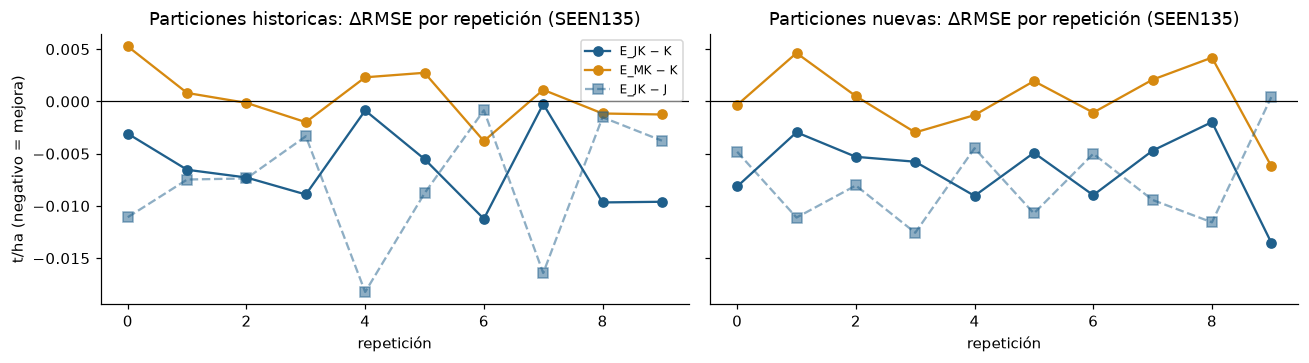

In [7]:
S = w[w.municipio_visto]
pares = csv_insumo("pares_control")
vista = pares[pares.escenario.eq("SEEN135")].pivot_table(index=["candidato", "referencia"], columns="conjunto", values=["delta_RMSE", "delta_MAE", "reps_mejora_RMSE"])
display(vista.round(5))
rep = S.groupby(["conjunto", "repeticion"]).apply(lambda g: pd.Series({m: np.sqrt(((g[m] - g.observado) ** 2).mean()) for m in MODELOS}), include_groups=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for a, cj in zip(ax, ["historicas", "nuevas"]):
    r = rep.loc[cj]
    for m, c in [("E_JK", "#1f5f8b"), ("E_MK", "#d68910")]:
        a.plot(r.index, r[m] - r.K, "o-", color=c, label=f"{m} − K")
    a.plot(r.index, r.E_JK - r.J, "s--", color="#1f5f8b", alpha=0.5, label="E_JK − J")
    a.axhline(0, color="k", lw=0.8); a.set_title(f"Particiones {cj}: ΔRMSE por repetición (SEEN135)"); a.set_xlabel("repetición")
ax[0].set_ylabel("t/ha (negativo = mejora)"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
ctrl_rep = csv_insumo("repeticiones_control")
c = ctrl_rep[ctrl_rep.escenario.eq("SEEN135")].pivot_table(index=["conjunto", "repeticion"], columns="modelo", values="RMSE")[MODELOS]
assert np.allclose(rep[MODELOS].to_numpy(), c.loc[rep.index].to_numpy(), atol=1e-12, rtol=0)

**Lectura de las tablas (SEEN135):**

* **E_JK** baja el RMSE del mejor componente (K) en **≈0.0063 t/ha (históricas) y ≈0.0066 (nuevas)**, y el de MIX en ≈0.0115 (~2.4 %). Mejora a K en 10/10 repeticiones de ambos juegos, y a J en 10/10 y 9/10.
* El **MAE** de E_JK (≈0.3214 / 0.3225) mejora a MIX, J y K. Queda prácticamente igual al de MUN: +0.0001 en históricas y +0.0011 en nuevas, ligeramente peor. Es un compromiso pequeño, pero existe.
* **E_MK no supera a K** en RMSE: +0.0004 y +0.0001, con 5/10 repeticiones en cada juego. Solo bajar el peso de la interpolación **no reproduce** la ganancia.
* **E_JK frente a E_MK:** −0.0067 en ambos juegos, 10/10 repeticiones. La diferencia entre las dos mezclas está en lo que aporta J.

### 6.2 Por qué funciona: errores muy parecidos, correcciones distintas

Hay dos correlaciones que **no deben confundirse**:

* **Entre errores** (ŷ − y): mide cuánto fallan juntos.
* **Entre cambios respecto a MIX** (ŷ − MIX): mide si corrigen en la misma dirección.

In [8]:
corr = csv_insumo("correlaciones_control")
display(corr.pivot(index=["tipo", "par"], columns="conjunto", values="pearson").round(3))
for cj in ["historicas", "nuevas"]:
    o = S[S.conjunto == cj]; ej, ek = o.J - o.observado, o.K - o.observado
    izq = ((0.5 * o.J + 0.5 * o.K - o.observado) ** 2).mean()
    der = 0.25 * (ej ** 2).mean() + 0.25 * (ek ** 2).mean() + 0.5 * (ej * ek).mean()
    assert abs(izq - der) < 1e-14
    print(f"{cj}: MSE_J={np.mean(ej**2):.5f}  MSE_K={np.mean(ek**2):.5f}  promedio(e_J·e_K)={np.mean(ej*ek):.5f}  ⇒ MSE(E_JK)={izq:.5f}")

conjunto                         historicas  nuevas
tipo           par                                 
cambios_vs_MIX J−MIX vs K−MIX         0.029   0.044
               MUN−MIX vs K−MIX      -0.041  -0.027
errores        J vs K                 0.942   0.941
               MUN vs K               0.956   0.955

historicas: MSE_J=0.23381  MSE_K=0.23231  promedio(e_J·e_K)=0.21944  ⇒ MSE(E_JK)=0.22625
nuevas: MSE_J=0.23246  MSE_K=0.23132  promedio(e_J·e_K)=0.21823  ⇒ MSE(E_JK)=0.22506


Los errores de J y K se parecen mucho (≈0.94): ambos fallan juntos en las parcelas difíciles, porque ambos parten del territorio. Sus **correcciones** respecto a MIX casi no se parecen (≈0.03). La fórmula muestra que basta esa pequeña parte no compartida para bajar el MSE. **Ninguna de las dos correlaciones prueba la mejora por sí sola: la prueba es la tabla de la sección 6.1.**

### 6.3 ¿Dónde mejora? Zonas y municipios

Los municipios con menos de 10 parcelas evaluadas (Cuautepec 5, Emiliano Zapata 3) dan cifras muy inestables: se muestran, pero no se interpretan.

In [9]:
z = csv_insumo("zonas_control").pivot_table(index=["conjunto", "zona"], columns="modelo", values="RMSE")[MODELOS]
display(z.round(4))
mu = csv_insumo("municipios_control")
display(mu[mu.conjunto.eq("historicas")].pivot_table(index=["Municipio", "n_parcelas", "muestra_pequena"], columns="modelo", values="RMSE")[MODELOS].round(4))

modelo                      MIX     MUN       J       K    E_JK    E_MK
conjunto   zona                                                        
historicas Chignahuapan  0.5736  0.5902  0.5755  0.5687  0.5664  0.5744
           resto         0.3683  0.3565  0.3546  0.3623  0.3483  0.3532
nuevas     Chignahuapan  0.5692  0.5883  0.5753  0.5648  0.5642  0.5711
           resto         0.3716  0.3564  0.3510  0.3661  0.3486  0.3555

,,modelo,MIX,MUN,J,K,E_JK,E_MK
Municipio,n_parcelas,muestra_pequena,,,,,,
Almoloya,10,False,0.1794,0.2007,0.2025,0.1719,0.1720,0.1823
Calpulalpan,30,False,0.4013,0.3790,0.3794,0.4023,0.3845,0.3850
Chignahuapan,71,False,0.5736,0.5902,0.5755,0.5687,0.5664,0.5744
Cuautepec de Hinojosa,5,True,0.2604,0.1655,0.2083,0.2394,0.1973,0.1928
Emiliano Zapata,3,True,0.1382,0.0000,0.2897,0.1382,0.1481,0.0691
Singuilucan,16,False,0.4424,0.4531,0.4221,0.4264,0.4163,0.4333


E_JK es la mejor opción tanto en **Chignahuapan** como en el **resto**, en ambos juegos. Por municipio no domina en todas partes. En **Calpulalpan** (30 parcelas), MUN y J siguen siendo mejores que E_JK. **No se construyen reglas por municipio con estos resultados**; eso sería una búsqueda nueva.

### 6.4 ¿Está concentrada la ganancia?

Orden declarado antes de calcular: por parcela, Δ = Σ_repeticiones [(error de la mezcla)² − (error de la referencia)²], de la más favorecida a la menos. Retiramos **solo de la evaluación** las 2 y las 5 primeras. No es una nueva estimación imparcial; todas las parcelas se quedan en los ajustes originales.

In [10]:
sens = csv_insumo("sensibilidades_control")
display(sens.pivot_table(index=["candidato", "referencia", "retiradas"], columns="conjunto", values="delta_RMSE").round(5))

conjunto                        historicas   nuevas
candidato referencia retiradas                     
E_JK      K          0            -0.00633 -0.00656
                     2            -0.00347 -0.00365
                     5            -0.00081 -0.00061
          MIX        0            -0.01154 -0.01127
                     2            -0.00818 -0.00829
                     5            -0.00444 -0.00470
E_MK      K          0             0.00037  0.00011
                     2             0.00424  0.00406
                     5             0.00755  0.00753
          MIX        0            -0.00485 -0.00460
                     2            -0.00245 -0.00217
                     5             0.00021  0.00074

* **Frente a K (su mejor componente):** E_JK sigue mejorando sin las 2 más favorecidas (−0.0035 / −0.0037) y sin las 5 (−0.0008 / −0.0006). La ventaja se reduce mucho, pero no se invierte.
* **Frente a MIX:** se mantiene clara aun sin 5 parcelas (−0.0044 / −0.0047).
* **E_MK frente a K:** empeora en cuanto se quitan parcelas.

**Sensibilidad FULL138.** Incluye 3 parcelas cuyo municipio tiene una sola etiqueta (AGC_047, AGC_048, AGC_164). Cuando se validan, MUN no tiene media de su municipio y usa la media global. J usa su grupo regional y ahí es claramente mejor.

In [11]:
display(MET[MET.escenario.eq("FULL138")].pivot(index="modelo", columns="conjunto", values=["RMSE", "MAE"]).reindex(MODELOS).round(4))
display(csv_insumo("no_vistos_control").pivot(index="modelo", columns="conjunto", values="RMSE").reindex(MODELOS).round(4))

RMSE                MAE        
conjunto historicas  nuevas historicas  nuevas
modelo                                        
MIX          0.4938  0.4923     0.3417  0.3430
MUN          0.5118  0.5110     0.3354  0.3356
J            0.4833  0.4819     0.3328  0.3328
K            0.4879  0.4870     0.3398  0.3413
E_JK         0.4775  0.4764     0.3255  0.3266
E_MK         0.4938  0.4929     0.3317  0.3329

conjunto,historicas,nuevas
modelo,,
MIX,0.7331,0.7310
MUN,1.0450,1.0525
J,0.4729,0.4722
K,0.7058,0.7075
E_JK,0.5560,0.5583
E_MK,0.8652,0.8716


## 7. Lectura y decisión

Criterio fijado antes de calcular (no es regla de adopción):

* **A:** no supera al mejor componente en algún juego.
* **B:** lo supera en ambos, pero con menos de 8/10 repeticiones frente a algún componente, o la ganancia se invierte sin las 2 parcelas más favorecidas.
* **C:** lo supera de forma consistente en ambos juegos.

Para atribuir algo a Jared se exige E_JK < E_MK en ambos juegos, con ≥8/10 repeticiones.

In [12]:
lectura = csv_insumo("lectura_control").set_index("mezcla")
display(lectura.T)
clases = REG["clases"]; aporte = REG["aporte_especifico_J"]
print("Clases:", clases, "| aporte específico de J sobre el control:", aporte)
assert clases == {"E_JK": "C", "E_MK": "A"} and aporte is True
resumen = {"id": "EXP_11", "modo": "lector_exploratorio_sin_entrenamientos", "filas_por_modelo": 2760, "formulas": 2,
           "entrenamientos": 0, "busqueda_pesos": 0, "predicciones_59": 0, "clases": clases, "aporte_especifico_J": aporte,
           "rmse_seen": {f"{m}|{cj}": float(tabla.loc[m, ("RMSE", cj)]) for m in MODELOS for cj in ["historicas", "nuevas"]},
           "metricas_recalculadas": True, "colab_real_probado": False}
print("RESUMEN_EXP_11_JSON=" + json.dumps(resumen, ensure_ascii=False, sort_keys=True))

mezcla,E_JK,E_MK
componentes,J+K,MUN+K
clase,C,A
supera_mejor_componente_historicas,True,False
supera_mejor_componente_nuevas,True,False
reps_vs_J_historicas,10.0,NaN
reps_vs_K_historicas,10,5
reps_vs_J_nuevas,9.0,NaN
reps_vs_K_nuevas,10,5
sens2_vs_mejor_historicas,-0.003465,0.004237
sens2_vs_mejor_nuevas,-0.00365,0.004063


Clases: {'E_JK': 'C', 'E_MK': 'A'} | aporte específico de J sobre el control: True
RESUMEN_EXP_11_JSON={"aporte_especifico_J": true, "busqueda_pesos": 0, "clases": {"E_JK": "C", "E_MK": "A"}, "colab_real_probado": false, "entrenamientos": 0, "filas_por_modelo": 2760, "formulas": 2, "id": "EXP_11", "metricas_recalculadas": true, "modo": "lector_exploratorio_sin_entrenamientos", "predicciones_59": 0, "rmse_seen": {"E_JK|historicas": 0.47565539767390236, "E_JK|nuevas": 0.4744037948122818, "E_MK|historicas": 0.4823462454047803, "E_MK|nuevas": 0.4810736531996574, "J|historicas": 0.48354033607356744, "J|nuevas": 0.4821384522461495, "K|historicas": 0.48198075658497197, "K|nuevas": 0.4809604605838424, "MIX|historicas": 0.48719651492000826, "MIX|nuevas": 0.4856700867043451, "MUN|historicas": 0.49340403132471566, "MUN|nuevas": 0.4922162077035042}}


### Qué permite decidir esta ronda

* **E_JK** queda en la clase **C**. En estos datos se observa **complementariedad predictiva** entre el modelo regional de Jared y la corrección local de K. Merece revisarse como candidato.
* **E_MK** queda en la clase **A**. El control muestra que la ganancia **no** se explica solo por reducir el peso de la interpolación.

### Qué **todavía no** permite decidir

* **No es un modelo final ni una adopción automática.** La hipótesis nació después de ver los resultados, sobre las mismas etiquetas. Los dos juegos de particiones no son independientes.
* **K hereda su propia selección exploratoria.** K1 se eligió en EXP_08 viendo las etiquetas, y en EXP_10 no alcanzó evidencia estadística suficiente. E_JK no borra esas reservas.
* **No hay un nulo estadístico para la mezcla en esta ronda.** La lectura es predictiva, no una prueba de significancia.
* **No dice nada sobre causalidad agronómica** ni sobre generalización a otras campañas o regiones.
* **No se han generado las 59 predicciones.** Para ellas haría falta revisar el soporte de J y K en las ocultas, incluido el caso de Nanacamilpa.

**Continuaciones posibles, NO ejecutadas:** otros pesos (25/75, 75/25), stacking, gating y mezclas regionales. Cualquiera de ellas exigiría un protocolo propio y aumentaría el riesgo de ajustarse a estas mismas etiquetas. La ablación completa sin territorio es otra pregunta y se planificará por separado.

**Reproducir:** `scripts/preparar_exp_11.py` (insumos y verificación de J), `scripts/experimento_11.py --salida <nueva>`, `scripts/verificar_exp_11_resultados.py` y `pytest tests/test_combinacion_11.py`.